# Comparação entre Instituições Públicas e Privadas: Evolução da Oferta de Vagas, Ingressos e Conclusões

**Disciplina:** Linguagens de Programação<br>
**Alunos:** Anna Clara Berce e João Pedro Torres<br>
**Curso:** Sistemas de Informação<br>
**Período analisado:** 2020 - 2023 <br>
**Fonte dos dados:** Instituto Nacional de Estudos e Pesquisas Educacionais Anísio Teixeira (INEP)

---

# Preparação Consolidada, Análise Temporal e Resultados Completos (2020–2023)

## Objetivo e Arquitetura do Pipeline
Este notebook faz parte do desenvolvimento do Projeto Final da disciplina de Linguagens de Programação. O objetivo principal deste estudo é explorar, tratar e analisar os microdados oficiais do Censo da Educação Superior, disponibilizados pelo INEP (Instituto Nacional de Estudos e Pesquisas Educacionais Anísio Teixeira).

Através da utilização de bibliotecas de manipulação e visualização em Python (como pandas, numpy, matplotlib, seaborn e plotly), este pipeline visa extrair insights relevantes sobre o cenário educacional após a Pandemia da COVID 19, estruturando os resultados de forma reprodutível para publicação em ambiente web (GitHub Pages).

Este notebook consolida a base de dados e executando a análise completa — descritiva, temporal, estratificada, inferencial e regional — para responder às três perguntas de pesquisa:

- **RQ1:** Qual é a diferença proporcional na evolução do número de vagas ofertadas e de ingressantes entre as instituições de ensino superior públicas e privadas nos últimos anos disponíveis do Censo?
- **RQ2:** Existe correlação estatística significativa entre a categoria administrativa da instituição (Pública vs. Privada) e a taxa de conclusão de cursos de graduação?
- **RQ3:** Como se distribui a oferta de vagas nas modalidades presencial e a distância quando comparadas entre as redes pública e privada em âmbito regional?

### Diretrizes de Armazenamento e Desempenho

1. **Processamento e saídas exclusivamente em memória:** Nenhuma pasta externa (como `resultados/`) ou arquivo CSV intermediário é criado. Todas as tabelas, testes estatísticos e visualizações são exibidos diretamente no notebook.
2. **Persistência restrita a `data/processed/`:** O único arquivo gravado em disco é a base consolidada, filtrada e tipada em `data/processed/censo_superior_2020_2023_graduacao.parquet`.
3. **Otimização de memória e harmonização de esquema:** Leitura seletiva apenas das colunas comuns necessárias (`columns=[...]`), tipagem numérica explícita e padronização dos domínios do Inep (2020–2023).

## 1. Preparação do ambiente e configuração de caminhos

In [ ]:
from pathlib import Path
from itertools import combinations
import gc
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pyarrow.parquet as pq
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)

# Configuração visual padrão para os gráficos em memória
plt.rcParams["figure.figsize"] = (11, 5.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.size"] = 10

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [ ]:
# Diretórios do projeto (sem criação de pastas externas como 'resultados')
PASTA_RAW = Path("data/raw")
PASTA_PROCESSED = Path("data/processed")
PASTA_PROCESSED.mkdir(parents=True, exist_ok=True)

ARQUIVOS_RAW = {
    2020: PASTA_RAW / "censo_superior_2020.parquet",
    2021: PASTA_RAW / "censo_superior_2021.parquet",
    2022: PASTA_RAW / "censo_superior_2022.parquet",
    2023: PASTA_RAW / "censo_superior_2023.parquet",
}

# Único arquivo persistido em disco: base limpa e pronta para análise
ARQUIVO_PROCESSADO = PASTA_PROCESSED / "censo_superior_2020_2023_graduacao.parquet"

print(f"Diretório de entrada : {PASTA_RAW.resolve()}")
print(f"Arquivo de saída     : {ARQUIVO_PROCESSADO.resolve()}")

Diretório de entrada : /content/data/raw
Arquivo de saída     : /content/data/processed/censo_superior_2020_2023_graduacao.parquet


## 2. Tratamento, consolidação e geração da base analítica (`data/processed`)

Com base no diagnóstico do Notebook 01, aplicamos os seguintes critérios metodológicos:

- **Seleção de colunas comuns (2020–2023):** Carrega apenas as 23 colunas analíticas essenciais, eliminando diferenças de esquema entre edições (`CO_CINE_ROTULO2` em 2020 e `IN_COMUNITARIA`/`IN_CONFESSIONAL` em 2023) e reduzindo o uso de memória de ~19 GB acumulados para menos de 160 MB.
- **Filtro de nível acadêmico (`TP_NIVEL_ACADEMICO == '1'`):** Mantém exclusivamente os **cursos de graduação**, removendo cursos sequenciais de formação específica (`TP_NIVEL_ACADEMICO == '2'`).
- **Tipagem numérica e categorização:** Converte colunas quantitativas armazenadas como `string` nos arquivos brutos (`QT_VG_NOVA`, `QT_INSCRITO_TOTAL`, etc.) para `int64` e decodifica `TP_REDE`, `TP_CATEGORIA_ADMINISTRATIVA`, `TP_MODALIDADE_ENSINO`, `TP_GRAU_ACADEMICO` e `IN_CAPITAL`.
- **Tratamento de `NO_REGIAO` e `IN_CAPITAL` ausentes:** Registros sem `NO_REGIAO` (~1,7% a 1,8% das linhas) correspondem às ofertas EaD sem vinculação municipal/polo (`TP_DIMENSAO` 3 e 4, como polos no exterior). São rotulados como `"Não informada / Exterior (EaD)"` para preservar os totais nacionais na **RQ1** e **RQ2** e isolados com transparência na análise regional da **RQ3**.

In [ ]:
COLUNAS_SELECIONADAS = [
    "NU_ANO_CENSO",
    "NO_REGIAO",
    "CO_REGIAO",
    "SG_UF",
    "NO_UF",
    "IN_CAPITAL",
    "TP_DIMENSAO",
    "TP_ORGANIZACAO_ACADEMICA",
    "TP_CATEGORIA_ADMINISTRATIVA",
    "TP_REDE",
    "CO_IES",
    "CO_CURSO",
    "NO_CURSO",
    "NO_CINE_AREA_GERAL",
    "TP_GRAU_ACADEMICO",
    "TP_MODALIDADE_ENSINO",
    "TP_NIVEL_ACADEMICO",
    "QT_VG_TOTAL",
    "QT_VG_NOVA",
    "QT_INSCRITO_TOTAL",
    "QT_ING",
    "QT_MAT",
    "QT_CONC",
]

COLUNAS_NUMERICAS = [
    "QT_VG_TOTAL",
    "QT_VG_NOVA",
    "QT_INSCRITO_TOTAL",
    "QT_ING",
    "QT_MAT",
    "QT_CONC",
]

MAPA_REDE = {
    "1": "Pública",
    "2": "Privada",
}

MAPA_CATEGORIA_ADM = {
    "1": "Pública Federal",
    "2": "Pública Estadual",
    "3": "Pública Municipal",
    "4": "Privada com fins lucrativos",
    "5": "Privada sem fins lucrativos",
    "7": "Especial",
}

MAPA_MODALIDADE = {
    "1": "Presencial",
    "2": "EaD",
}

MAPA_GRAU = {
    "1": "Bacharelado",
    "2": "Licenciatura",
    "3": "Tecnológico",
}

MAPA_CAPITAL = {
    "0": "Interior",
    "1": "Capital",
}

COLUNAS_DERIVADAS_ESPERADAS = {
    "REDE", "CATEGORIA_ADM", "MODALIDADE", "GRAU_ACADEMICO", "LOCALIDADE", "REGIAO"
}


def construir_base_analitica(arquivos_raw: dict, destino_parquet: Path, forcar_reprocessamento: bool = False) -> pd.DataFrame:
    """Consolida os microdados de 2020 a 2023, aplica tratamentos e salva apenas a base final em data/processed."""
    if destino_parquet.exists() and not forcar_reprocessamento:
        schema_atual = set(pq.read_schema(destino_parquet).names)
        if COLUNAS_DERIVADAS_ESPERADAS.issubset(schema_atual):
            print(f"Carregando base pronta para análise já existente: {destino_parquet}")
            return pd.read_parquet(destino_parquet, engine="pyarrow")
        print("Atualizando base em data/processed para incluir novas variáveis derivadas...")

    partes = []
    for ano, caminho in sorted(arquivos_raw.items()):
        if not caminho.exists():
            raise FileNotFoundError(f"Arquivo não encontrado para {ano}: {caminho}")

        df_ano = pd.read_parquet(caminho, columns=COLUNAS_SELECIONADAS, engine="pyarrow")

        # 1. Filtrar exclusivamente cursos de graduação (TP_NIVEL_ACADEMICO == '1')
        df_ano = df_ano[df_ano["TP_NIVEL_ACADEMICO"].astype(str) == "1"].copy()

        # 2. Garantir tipagem numérica das métricas quantitativas
        for col in COLUNAS_NUMERICAS:
            df_ano[col] = pd.to_numeric(df_ano[col], errors="coerce").fillna(0).astype("int64")

        df_ano["NU_ANO_CENSO"] = df_ano["NU_ANO_CENSO"].astype("int32")
        df_ano["CO_CURSO"] = df_ano["CO_CURSO"].astype("int64")

        # 3. Padronizar rótulos analíticos
        df_ano["REDE"] = df_ano["TP_REDE"].astype(str).map(MAPA_REDE).fillna("Não classificada")
        df_ano["CATEGORIA_ADM"] = (
            df_ano["TP_CATEGORIA_ADMINISTRATIVA"].astype(str).map(MAPA_CATEGORIA_ADM).fillna("Outra")
        )
        df_ano["MODALIDADE"] = (
            df_ano["TP_MODALIDADE_ENSINO"].astype(str).map(MAPA_MODALIDADE).fillna("Não informada")
        )
        df_ano["GRAU_ACADEMICO"] = (
            df_ano["TP_GRAU_ACADEMICO"].astype(str).map(MAPA_GRAU).fillna("Outro / Não informado")
        )
        df_ano["LOCALIDADE"] = (
            df_ano["IN_CAPITAL"].astype(str).map(MAPA_CAPITAL).fillna("Não informada / Exterior (EaD)")
        )
        df_ano["REGIAO"] = (
            df_ano["NO_REGIAO"]
            .astype("string")
            .fillna("Não informada / Exterior (EaD)")
            .astype(str)
        )

        # 4. Otimizar colunas categóricas para reduzir memória
        cols_categoricas = [
            "REGIAO", "SG_UF", "NO_UF", "IN_CAPITAL", "LOCALIDADE",
            "TP_DIMENSAO", "TP_ORGANIZACAO_ACADEMICA", "TP_CATEGORIA_ADMINISTRATIVA",
            "TP_REDE", "REDE", "CATEGORIA_ADM", "NO_CINE_AREA_GERAL",
            "TP_GRAU_ACADEMICO", "GRAU_ACADEMICO", "TP_MODALIDADE_ENSINO",
            "MODALIDADE", "TP_NIVEL_ACADEMICO"
        ]
        for col in cols_categoricas:
            df_ano[col] = df_ano[col].astype("category")

        partes.append(df_ano)
        print(f"{ano}: {len(df_ano):,} registros de graduação processados.")

        del df_ano
        gc.collect()

    df_consolidado = pd.concat(partes, ignore_index=True)
    del partes
    gc.collect()

    # Salva exclusivamente o arquivo pronto para análise em data/processed
    df_consolidado.to_parquet(destino_parquet, index=False, engine="pyarrow")
    tamanho_mb = destino_parquet.stat().st_size / (1024 ** 2)
    print(f"\nBase consolidada salva com sucesso em: {destino_parquet} ({tamanho_mb:.2f} MB)")

    return df_consolidado


df_grad = construir_base_analitica(ARQUIVOS_RAW, ARQUIVO_PROCESSADO)
print(f"Dimensões finais em memória: {df_grad.shape}")
display(df_grad.head())

2020: 344,665 registros de graduação processados.
2021: 444,769 registros de graduação processados.
2022: 573,010 registros de graduação processados.
2023: 671,605 registros de graduação processados.

Base consolidada salva com sucesso em: data/processed/censo_superior_2020_2023_graduacao.parquet (14.18 MB)
Dimensões finais em memória: (2034049, 29)


,NU_ANO_CENSO,NO_REGIAO,CO_REGIAO,SG_UF,NO_UF,IN_CAPITAL,TP_DIMENSAO,TP_ORGANIZACAO_ACADEMICA,TP_CATEGORIA_ADMINISTRATIVA,TP_REDE,CO_IES,CO_CURSO,NO_CURSO,NO_CINE_AREA_GERAL,TP_GRAU_ACADEMICO,TP_MODALIDADE_ENSINO,TP_NIVEL_ACADEMICO,QT_VG_TOTAL,QT_VG_NOVA,QT_INSCRITO_TOTAL,QT_ING,QT_MAT,QT_CONC,REDE,CATEGORIA_ADM,MODALIDADE,GRAU_ACADEMICO,LOCALIDADE,REGIAO
0,2020,<NA>,<NA>,<NA>,<NA>,<NA>,3,1,1,1,1,1113617,ADMINISTRAÇÃO PÚBLICA,"Negócios, administração e direito",1,2,1,0,0,0,0,0,0,Pública,Pública Federal,EaD,Bacharelado,Não informada / Exterior (EaD),Não informada / Exterior (EaD)
1,2020,<NA>,<NA>,<NA>,<NA>,<NA>,3,1,1,1,1,114386,CIÊNCIAS NATURAIS E MATEMÁTICA,Educação,2,2,1,0,0,0,0,0,0,Pública,Pública Federal,EaD,Licenciatura,Não informada / Exterior (EaD),Não informada / Exterior (EaD)
2,2020,<NA>,<NA>,<NA>,<NA>,<NA>,3,1,1,1,1,1357965,MATEMÁTICA,Educação,2,2,1,0,0,0,0,0,0,Pública,Pública Federal,EaD,Licenciatura,Não informada / Exterior (EaD),Não informada / Exterior (EaD)
3,2020,<NA>,<NA>,<NA>,<NA>,<NA>,3,1,1,1,1,105652,PEDAGOGIA,Educação,2,2,1,216,216,282,0,0,0,Pública,Pública Federal,EaD,Licenciatura,Não informada / Exterior (EaD),Não informada / Exterior (EaD)
4,2020,<NA>,<NA>,<NA>,<NA>,<NA>,3,1,1,1,1,1425400,TECNOLOGIA EDUCACIONAL,Educação,2,2,1,210,210,238,0,0,0,Pública,Pública Federal,EaD,Licenciatura,Não informada / Exterior (EaD),Não informada / Exterior (EaD)


## 3. RQ1 — Evolução Temporal de Vagas Ofertadas e Ingressantes (Pública vs. Privada)

**Pergunta de Pesquisa (RQ1):** *Qual é a diferença proporcional na evolução do número de vagas ofertadas e de ingressantes entre as instituições de ensino superior públicas e privadas nos últimos anos disponíveis do Censo?*

### 3.1 Evolução Agregada, Participação Proporcional (*Market Share*) e Índice Base 100
1. **Volume Absoluto Anual:** Soma de vagas totais (`QT_VG_TOTAL`), vagas novas (`QT_VG_NOVA`), inscritos (`QT_INSCRITO_TOTAL`), ingressantes (`QT_ING`), matrículas (`QT_MAT`) e concluintes (`QT_CONC`) por ano e rede.
2. **Participação Proporcional (*Market Share*, %):** Fatia de cada rede sobre o total nacional em cada edição do Censo e variação em pontos percentuais ($\Delta\text{ p.p.}$) entre 2020 e 2023.
3. **Taxa de Crescimento Acumulada, CAGR e Índice Base 100 (`2020 = 100`):** Compara a velocidade relativa de expansão entre as redes pública e privada.
4. **Indicadores de Demanda e Ociosidade:** **Taxa de Ocupação** (`Ingressantes / Vagas Ofertadas`), **Relação Candidato/Vaga** (`Inscritos / Vagas Ofertadas`) e **Aproveitamento de Vagas Novas** (`Ingressantes / Vagas Novas`).

In [ ]:
# Agregação anual por rede de ensino (Pública vs. Privada)
rq1_anual = (
    df_grad.groupby(["NU_ANO_CENSO", "REDE"], observed=True)[COLUNAS_NUMERICAS]
    .sum()
    .reset_index()
)

# Totais anuais nacionais para cálculo das proporções (Market Share)
totais_ano = (
    rq1_anual.groupby("NU_ANO_CENSO")[COLUNAS_NUMERICAS]
    .transform("sum")
)

rq1_anual["SHARE_VAGAS_PCT"] = (rq1_anual["QT_VG_TOTAL"] / totais_ano["QT_VG_TOTAL"]) * 100
rq1_anual["SHARE_ING_PCT"] = (rq1_anual["QT_ING"] / totais_ano["QT_ING"]) * 100
rq1_anual["TAXA_OCUPACAO_PCT"] = (rq1_anual["QT_ING"] / rq1_anual["QT_VG_TOTAL"]) * 100
rq1_anual["CANDIDATO_POR_VAGA"] = rq1_anual["QT_INSCRITO_TOTAL"] / rq1_anual["QT_VG_TOTAL"].replace(0, np.nan)
rq1_anual["ING_SOBRE_VG_NOVA_PCT"] = (rq1_anual["QT_ING"] / rq1_anual["QT_VG_NOVA"].replace(0, np.nan)) * 100

# Índice Base 100 (ano base = 2020) e variação percentual ano a ano (YoY)
rq1_anual = rq1_anual.sort_values(["REDE", "NU_ANO_CENSO"]).reset_index(drop=True)
base_2020_vagas = rq1_anual.groupby("REDE", observed=True)["QT_VG_TOTAL"].transform("first")
base_2020_ing = rq1_anual.groupby("REDE", observed=True)["QT_ING"].transform("first")

rq1_anual["INDICE_VAGAS_2020"] = (rq1_anual["QT_VG_TOTAL"] / base_2020_vagas) * 100
rq1_anual["INDICE_ING_2020"] = (rq1_anual["QT_ING"] / base_2020_ing) * 100
rq1_anual["VAR_YOY_VAGAS_PCT"] = rq1_anual.groupby("REDE", observed=True)["QT_VG_TOTAL"].pct_change() * 100
rq1_anual["VAR_YOY_ING_PCT"] = rq1_anual.groupby("REDE", observed=True)["QT_ING"].pct_change() * 100

print("=== RQ1.1: Evolução Anual de Vagas, Ingressantes e Indicadores de Demanda (2020–2023) ===")
display(rq1_anual)

=== RQ1.1: Evolução Anual de Vagas, Ingressantes e Indicadores de Demanda (2020–2023) ===


,NU_ANO_CENSO,REDE,QT_VG_TOTAL,QT_VG_NOVA,QT_INSCRITO_TOTAL,QT_ING,QT_MAT,QT_CONC,SHARE_VAGAS_PCT,SHARE_ING_PCT,TAXA_OCUPACAO_PCT,CANDIDATO_POR_VAGA,ING_SOBRE_VG_NOVA_PCT,INDICE_VAGAS_2020,INDICE_ING_2020,VAR_YOY_VAGAS_PCT,VAR_YOY_ING_PCT
0,2020,Privada,18762921,13659249,14128854,3238469,6724002,1074448,95.60,86.00,17.26,0.75,23.71,100.00,100.00,NaN,NaN
1,2021,Privada,21850441,16237583,10637391,3452756,6907893,1107846,96.35,87.52,15.80,0.49,21.26,116.46,106.62,16.46,6.62
2,2022,Privada,21959144,16558229,12791069,4231328,7367080,1048682,96.19,88.95,19.27,0.58,25.55,117.03,130.66,0.50,22.55
3,2023,Privada,23681606,17610297,10163072,4424903,7907652,1117455,96.18,88.60,18.68,0.43,25.13,126.21,136.64,7.84,4.57
4,2020,Pública,863520,668890,5971329,527006,1956352,204174,4.40,14.00,61.03,6.92,78.79,100.00,100.00,NaN,NaN
5,2021,Pública,827045,646844,4482727,492141,2078661,219342,3.65,12.48,59.51,5.42,76.08,95.78,93.38,-4.22,-6.62
6,2022,Pública,870659,669239,4195709,525400,2076517,238774,3.81,11.05,60.35,4.82,78.51,100.83,99.70,5.27,6.76
7,2023,Pública,939929,682475,4350629,569089,2069130,257214,3.82,11.40,60.55,4.63,83.39,108.85,107.99,7.96,8.32


In [ ]:
# Síntese comparativa acumulada (2020 vs. 2023) e CAGR por rede
anos_extremos = [rq1_anual["NU_ANO_CENSO"].min(), rq1_anual["NU_ANO_CENSO"].max()]
n_periodos = anos_extremos[1] - anos_extremos[0]

piv_rq1 = rq1_anual[rq1_anual["NU_ANO_CENSO"].isin(anos_extremos)].pivot(
    index="REDE",
    columns="NU_ANO_CENSO",
    values=["QT_VG_TOTAL", "SHARE_VAGAS_PCT", "QT_ING", "SHARE_ING_PCT", "TAXA_OCUPACAO_PCT", "CANDIDATO_POR_VAGA"]
)

resumo_rq1 = pd.DataFrame(index=piv_rq1.index)
resumo_rq1["Vagas_2020"] = piv_rq1[("QT_VG_TOTAL", anos_extremos[0])]
resumo_rq1["Vagas_2023"] = piv_rq1[("QT_VG_TOTAL", anos_extremos[1])]
resumo_rq1["Var_Acum_Vagas_%"] = ((resumo_rq1["Vagas_2023"] / resumo_rq1["Vagas_2020"]) - 1) * 100
resumo_rq1["CAGR_Vagas_%"] = ((resumo_rq1["Vagas_2023"] / resumo_rq1["Vagas_2020"]) ** (1 / n_periodos) - 1) * 100
resumo_rq1["Delta_Share_Vagas_pp"] = (
    piv_rq1[("SHARE_VAGAS_PCT", anos_extremos[1])] - piv_rq1[("SHARE_VAGAS_PCT", anos_extremos[0])]
)

resumo_rq1["Ing_2020"] = piv_rq1[("QT_ING", anos_extremos[0])]
resumo_rq1["Ing_2023"] = piv_rq1[("QT_ING", anos_extremos[1])]
resumo_rq1["Var_Acum_Ing_%"] = ((resumo_rq1["Ing_2023"] / resumo_rq1["Ing_2020"]) - 1) * 100
resumo_rq1["CAGR_Ing_%"] = ((resumo_rq1["Ing_2023"] / resumo_rq1["Ing_2020"]) ** (1 / n_periodos) - 1) * 100
resumo_rq1["Delta_Share_Ing_pp"] = (
    piv_rq1[("SHARE_ING_PCT", anos_extremos[1])] - piv_rq1[("SHARE_ING_PCT", anos_extremos[0])]
)

print(f"=== RQ1.2: Síntese Proporcional ({anos_extremos[0]} vs. {anos_extremos[1]}) ===")
display(resumo_rq1)

diff_vagas_pp = np.nan
diff_ing_pp = np.nan
if {"Privada", "Pública"}.issubset(resumo_rq1.index):
    diff_vagas_pp = resumo_rq1.loc["Privada", "Var_Acum_Vagas_%"] - resumo_rq1.loc["Pública", "Var_Acum_Vagas_%"]
    diff_ing_pp = resumo_rq1.loc["Privada", "Var_Acum_Ing_%"] - resumo_rq1.loc["Pública", "Var_Acum_Ing_%"]
    print(f"Diferença na taxa de crescimento acumulado de VAGAS (Privada - Pública): {diff_vagas_pp:+.2f} p.p.")
    print(f"Diferença na taxa de crescimento acumulado de INGRESSANTES (Privada - Pública): {diff_ing_pp:+.2f} p.p.")

=== RQ1.2: Síntese Proporcional (2020 vs. 2023) ===


,Vagas_2020,Vagas_2023,Var_Acum_Vagas_%,CAGR_Vagas_%,Delta_Share_Vagas_pp,Ing_2020,Ing_2023,Var_Acum_Ing_%,CAGR_Ing_%,Delta_Share_Ing_pp
REDE,,,,,,,,,,
Privada,"18,762,921.00","23,681,606.00",26.21,8.07,0.58,"3,238,469.00","4,424,903.00",36.64,10.97,2.60
Pública,"863,520.00","939,929.00",8.85,2.87,-0.58,"527,006.00","569,089.00",7.99,2.59,-2.60


Diferença na taxa de crescimento acumulado de VAGAS (Privada - Pública): +17.37 p.p.
Diferença na taxa de crescimento acumulado de INGRESSANTES (Privada - Pública): +28.65 p.p.


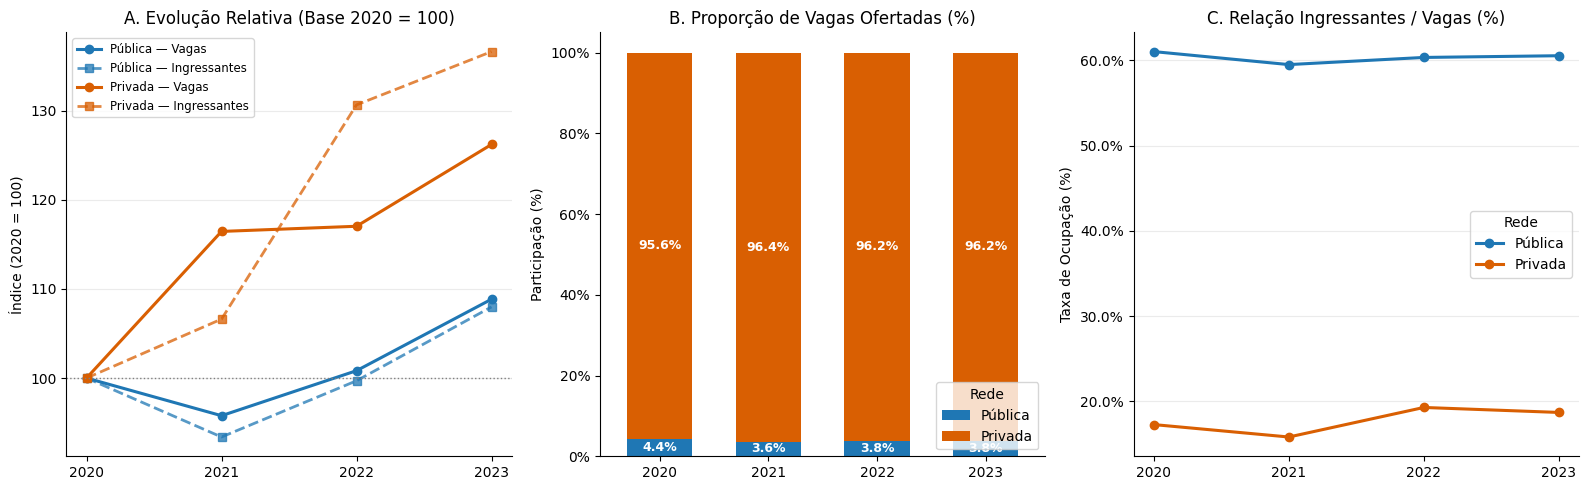

In [ ]:
# Visualização RQ1.1 (exibida diretamente em memória, sem exportação de arquivos)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
cores_rede = {"Pública": "#1f77b4", "Privada": "#d95f02"}

# Painel A: Índice Base 100 (2020 = 100) — Vagas vs. Ingressantes
for rede in ["Pública", "Privada"]:
    sub = rq1_anual[rq1_anual["REDE"] == rede]
    axes[0].plot(
        sub["NU_ANO_CENSO"], sub["INDICE_VAGAS_2020"],
        marker="o", linewidth=2.2, color=cores_rede[rede], label=f"{rede} — Vagas"
    )
    axes[0].plot(
        sub["NU_ANO_CENSO"], sub["INDICE_ING_2020"],
        marker="s", linestyle="--", linewidth=2.0, color=cores_rede[rede], alpha=0.75, label=f"{rede} — Ingressantes"
    )
axes[0].axhline(100, color="gray", linestyle=":", linewidth=1)
axes[0].set_title("A. Evolução Relativa (Base 2020 = 100)")
axes[0].set_ylabel("Índice (2020 = 100)")
axes[0].set_xticks([2020, 2021, 2022, 2023])
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend(fontsize=8.5)

# Painel B: Participação Proporcional (%) no Total Nacional
piv_share_vg = rq1_anual.pivot(index="NU_ANO_CENSO", columns="REDE", values="SHARE_VAGAS_PCT")[["Pública", "Privada"]]
piv_share_vg.plot(kind="bar", stacked=True, ax=axes[1], color=[cores_rede["Pública"], cores_rede["Privada"]], width=0.6)
axes[1].set_title("B. Proporção de Vagas Ofertadas (%)")
axes[1].set_ylabel("Participação (%)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", label_type="center", color="white", fontweight="bold", fontsize=9)
axes[1].legend(title="Rede", loc="lower right")

# Painel C: Taxa de Ocupação (Ingressantes / Vagas Ofertadas)
for rede in ["Pública", "Privada"]:
    sub = rq1_anual[rq1_anual["REDE"] == rede]
    axes[2].plot(
        sub["NU_ANO_CENSO"], sub["TAXA_OCUPACAO_PCT"],
        marker="o", linewidth=2.2, color=cores_rede[rede], label=rede
    )
axes[2].set_title("C. Relação Ingressantes / Vagas (%)")
axes[2].set_ylabel("Taxa de Ocupação (%)")
axes[2].set_xticks([2020, 2021, 2022, 2023])
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[2].grid(axis="y", alpha=0.25)
axes[2].legend(title="Rede")

plt.tight_layout()
plt.show()

### 3.2 Complemento RQ1 — Decomposição Estrutural por Modalidade, Categoria Administrativa, Grau e Área CINE

Para explicar **os vetores da diferença proporcional** entre as redes pública e privada, decompomos o crescimento de 2020 a 2023 por:
- **Segmento (`Rede × Modalidade`)** e **Categoria Administrativa Detalhada** (medindo a contribuição percentual de cada estrato para o saldo líquido de vagas e ingressos do país);
- **Grau Acadêmico (`Bacharelado`, `Licenciatura`, `Tecnológico`)**;
- **Áreas Gerais de Formação (`NO_CINE_AREA_GERAL`)**.

In [ ]:
# 1. Decomposição por Rede x Modalidade (2020 vs. 2023) e Contribuição ao Crescimento Total
decomp_mod = (
    df_grad[df_grad["NU_ANO_CENSO"].isin([2020, 2023])]
    .pivot_table(
        index=["REDE", "MODALIDADE"],
        columns="NU_ANO_CENSO",
        values=["QT_VG_TOTAL", "QT_VG_NOVA", "QT_ING"],
        aggfunc="sum",
        observed=True,
        fill_value=0
    )
)

res_decomp_mod = pd.DataFrame(index=decomp_mod.index)
res_decomp_mod["Vagas_2020"] = decomp_mod[("QT_VG_TOTAL", 2020)]
res_decomp_mod["Vagas_2023"] = decomp_mod[("QT_VG_TOTAL", 2023)]
res_decomp_mod["Delta_Vagas_Abs"] = res_decomp_mod["Vagas_2023"] - res_decomp_mod["Vagas_2020"]
res_decomp_mod["Var_Vagas_%"] = ((res_decomp_mod["Vagas_2023"] / res_decomp_mod["Vagas_2020"].replace(0, np.nan)) - 1) * 100
res_decomp_mod["Contrib_Cresc_Vagas_%"] = (
    res_decomp_mod["Delta_Vagas_Abs"] / res_decomp_mod["Delta_Vagas_Abs"].sum()
) * 100

res_decomp_mod["Ing_2020"] = decomp_mod[("QT_ING", 2020)]
res_decomp_mod["Ing_2023"] = decomp_mod[("QT_ING", 2023)]
res_decomp_mod["Delta_Ing_Abs"] = res_decomp_mod["Ing_2023"] - res_decomp_mod["Ing_2020"]
res_decomp_mod["Var_Ing_%"] = ((res_decomp_mod["Ing_2023"] / res_decomp_mod["Ing_2020"].replace(0, np.nan)) - 1) * 100
res_decomp_mod["Contrib_Cresc_Ing_%"] = (
    res_decomp_mod["Delta_Ing_Abs"] / res_decomp_mod["Delta_Ing_Abs"].sum()
) * 100

print("=== RQ1.3: Decomposição por Rede e Modalidade (2020 vs. 2023) ===")
display(res_decomp_mod)

# 2. Decomposição por Categoria Administrativa Detalhada
decomp_cat = (
    df_grad[df_grad["NU_ANO_CENSO"].isin([2020, 2023])]
    .pivot_table(
        index="CATEGORIA_ADM",
        columns="NU_ANO_CENSO",
        values=["QT_VG_TOTAL", "QT_ING"],
        aggfunc="sum",
        observed=True,
        fill_value=0
    )
)
res_decomp_cat = pd.DataFrame(index=decomp_cat.index)
res_decomp_cat["Vagas_2020"] = decomp_cat[("QT_VG_TOTAL", 2020)]
res_decomp_cat["Vagas_2023"] = decomp_cat[("QT_VG_TOTAL", 2023)]
res_decomp_cat["Var_Vagas_%"] = ((res_decomp_cat["Vagas_2023"] / res_decomp_cat["Vagas_2020"].replace(0, np.nan)) - 1) * 100
res_decomp_cat["Contrib_Cresc_Vagas_%"] = (
    (res_decomp_cat["Vagas_2023"] - res_decomp_cat["Vagas_2020"])
    / (res_decomp_cat["Vagas_2023"] - res_decomp_cat["Vagas_2020"]).sum()
) * 100
res_decomp_cat["Ing_2020"] = decomp_cat[("QT_ING", 2020)]
res_decomp_cat["Ing_2023"] = decomp_cat[("QT_ING", 2023)]
res_decomp_cat["Var_Ing_%"] = ((res_decomp_cat["Ing_2023"] / res_decomp_cat["Ing_2020"].replace(0, np.nan)) - 1) * 100
res_decomp_cat["Contrib_Cresc_Ing_%"] = (
    (res_decomp_cat["Ing_2023"] - res_decomp_cat["Ing_2020"])
    / (res_decomp_cat["Ing_2023"] - res_decomp_cat["Ing_2020"]).sum()
) * 100

print("\n=== RQ1.4: Decomposição por Categoria Administrativa Detalhada (2020 vs. 2023) ===")
display(res_decomp_cat)

=== RQ1.3: Decomposição por Rede e Modalidade (2020 vs. 2023) ===


Vagas_2020  Vagas_2023  Delta_Vagas_Abs  Var_Vagas_%  \
REDE    MODALIDADE                                                         
Privada EaD           13380045    19046990          5666945        42.35   
        Presencial     5382876     4634616          -748260       -13.90   
Pública EaD             136255      133976            -2279        -1.67   
        Presencial      727265      805953            78688        10.82   

                    Contrib_Cresc_Vagas_%  Ing_2020  Ing_2023  Delta_Ing_Abs  \
REDE    MODALIDADE                                                             
Privada EaD                        113.45   1960679   3226891        1266212   
        Presencial                 -14.98   1277790   1198012         -79778   
Pública EaD                         -0.05     48300     87511          39211   
        Presencial                   1.58    478706    481578           2872   

                    Var_Ing_%  Contrib_Cresc_Ing_%  
REDE    MODALIDADE                                  
Privada EaD             64.58               103.07  
        Presencial      -6.24                -6.49  
Pública EaD             81.18                 3.19  
        Presencial       0.60                 0.23


=== RQ1.4: Decomposição por Categoria Administrativa Detalhada (2020 vs. 2023) ===


,Vagas_2020,Vagas_2023,Var_Vagas_%,Contrib_Cresc_Vagas_%,Ing_2020,Ing_2023,Var_Ing_%,Contrib_Cresc_Ing_%
CATEGORIA_ADM,,,,,,,,
Especial,20477,40133,95.99,0.39,6701,10967,63.66,0.35
Privada com fins lucrativos,14017352,19064267,36.00,101.04,2600418,3696057,42.13,89.18
Privada sem fins lucrativos,4745569,4617339,-2.70,-2.57,638051,728846,14.23,7.39
Pública Estadual,247972,272069,9.72,0.48,163295,188068,15.17,2.02
Pública Federal,492599,593108,20.40,2.01,342526,353668,3.25,0.91
Pública Municipal,102472,34619,-66.22,-1.36,14484,16386,13.13,0.15


In [ ]:
# 3. Recorte por Grau Acadêmico e Áreas Gerais CINE (2020 vs. 2023)
decomp_grau = (
    df_grad[df_grad["NU_ANO_CENSO"].isin([2020, 2023])]
    .pivot_table(
        index=["REDE", "GRAU_ACADEMICO"],
        columns="NU_ANO_CENSO",
        values=["QT_VG_TOTAL", "QT_ING"],
        aggfunc="sum",
        observed=True,
        fill_value=0
    )
)
res_grau = pd.DataFrame(index=decomp_grau.index)
res_grau["Vagas_2020"] = decomp_grau[("QT_VG_TOTAL", 2020)]
res_grau["Vagas_2023"] = decomp_grau[("QT_VG_TOTAL", 2023)]
res_grau["Var_Vagas_%"] = ((res_grau["Vagas_2023"] / res_grau["Vagas_2020"].replace(0, np.nan)) - 1) * 100
res_grau["Ing_2020"] = decomp_grau[("QT_ING", 2020)]
res_grau["Ing_2023"] = decomp_grau[("QT_ING", 2023)]
res_grau["Var_Ing_%"] = ((res_grau["Ing_2023"] / res_grau["Ing_2020"].replace(0, np.nan)) - 1) * 100

print("=== RQ1.5: Evolução por Rede e Grau Acadêmico (2020 vs. 2023) ===")
display(res_grau)

# Top Áreas Gerais CINE por volume de ingressantes em 2023 e variação 2020–2023
cine_comp = (
    df_grad[df_grad["NU_ANO_CENSO"].isin([2020, 2023])]
    .pivot_table(
        index=["NO_CINE_AREA_GERAL", "REDE"],
        columns="NU_ANO_CENSO",
        values=["QT_VG_TOTAL", "QT_ING"],
        aggfunc="sum",
        observed=True,
        fill_value=0
    )
)
res_cine = pd.DataFrame(index=cine_comp.index)
res_cine["Vagas_2020"] = cine_comp[("QT_VG_TOTAL", 2020)]
res_cine["Vagas_2023"] = cine_comp[("QT_VG_TOTAL", 2023)]
res_cine["Var_Vagas_%"] = ((res_cine["Vagas_2023"] / res_cine["Vagas_2020"].replace(0, np.nan)) - 1) * 100
res_cine["Ing_2020"] = cine_comp[("QT_ING", 2020)]
res_cine["Ing_2023"] = cine_comp[("QT_ING", 2023)]
res_cine["Var_Ing_%"] = ((res_cine["Ing_2023"] / res_cine["Ing_2020"].replace(0, np.nan)) - 1) * 100

print("\n=== RQ1.6: Evolução por Área Geral CINE e Rede (2020 vs. 2023) ===")
display(res_cine.sort_values("Ing_2023", ascending=False))

=== RQ1.5: Evolução por Rede e Grau Acadêmico (2020 vs. 2023) ===


Vagas_2020  Vagas_2023  Var_Vagas_%  Ing_2020  \
REDE    GRAU_ACADEMICO                                                         
Privada Bacharelado               8354303     9686891        15.95   1777372   
        Licenciatura              3479716     4083219        17.34    544849   
        Outro / Não informado        4418       51467     1,064.94       952   
        Tecnológico               6924484     9860029        42.39    915296   
Pública Bacharelado                448253      494894        10.41    296147   
        Licenciatura               295650      303584         2.68    150941   
        Outro / Não informado       21482       23865        11.09     15050   
        Tecnológico                 98135      117586        19.82     64868   

                               Ing_2023  Var_Ing_%  
REDE    GRAU_ACADEMICO                              
Privada Bacharelado             2344110      31.89  
        Licenciatura             667202      22.46  
        Outro / Não informado     20768   2,081.51  
        Tecnológico             1392823      52.17  
Pública Bacharelado              312440       5.50  
        Licenciatura             160083       6.06  
        Outro / Não informado     16327       8.49  
        Tecnológico               80239      23.70


=== RQ1.6: Evolução por Área Geral CINE e Rede (2020 vs. 2023) ===


,,Vagas_2020,Vagas_2023,Var_Vagas_%,Ing_2020,Ing_2023,Var_Ing_%
NO_CINE_AREA_GERAL,REDE,,,,,,
"Negócios, administração e direito",Privada,6209527,7384909,18.93,1179534,1394604,18.23
Saúde e bem-estar,Privada,2835852,3427129,20.85,645312,970664,50.42
Educação,Privada,3509986,4198111,19.60,551028,687238,24.72
Computação e Tecnologias da Informação e Comunicação (TIC),Privada,1485865,2760482,85.78,188239,423614,125.04
"Engenharia, produção e construção",Privada,1944905,2071240,6.50,226080,273148,20.82
"Ciências sociais, comunicação e informação",Privada,797007,1185642,48.76,150886,212133,40.59
Serviços,Privada,1041515,1307105,25.50,133570,198019,48.25
Educação,Pública,295893,303829,2.68,151150,160276,6.04
Artes e humanidades,Privada,567523,771163,35.88,84360,123318,46.18


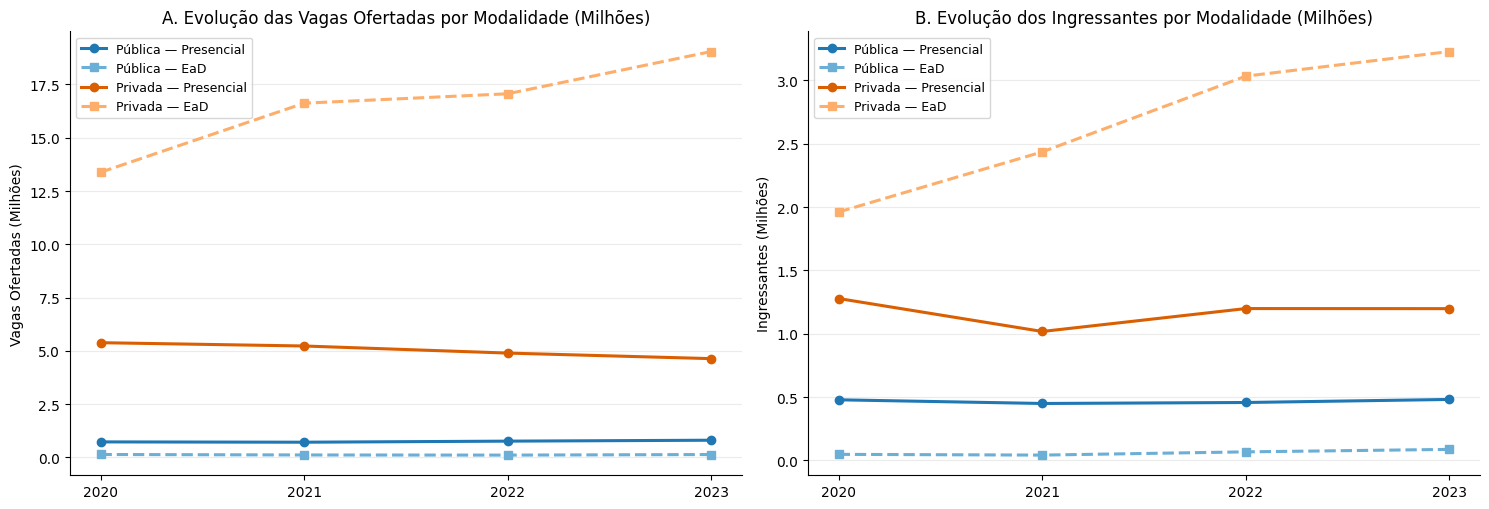

In [ ]:
# Visualização RQ1.2: Evolução por Rede x Modalidade (2020–2023)
rq1_mod_anual = (
    df_grad.groupby(["NU_ANO_CENSO", "REDE", "MODALIDADE"], observed=True)[["QT_VG_TOTAL", "QT_ING"]]
    .sum()
    .reset_index()
)
rq1_mod_anual["SEGMENTO"] = rq1_mod_anual["REDE"].astype(str) + " — " + rq1_mod_anual["MODALIDADE"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
estilos_seg = {
    "Pública — Presencial": ("#1f77b4", "-", "o"),
    "Pública — EaD": ("#6baed6", "--", "s"),
    "Privada — Presencial": ("#d95f02", "-", "o"),
    "Privada — EaD": ("#fdae6b", "--", "s"),
}

for seg, (cor, ls, mk) in estilos_seg.items():
    sub = rq1_mod_anual[rq1_mod_anual["SEGMENTO"] == seg].sort_values("NU_ANO_CENSO")
    axes[0].plot(sub["NU_ANO_CENSO"], sub["QT_VG_TOTAL"] / 1e6, color=cor, linestyle=ls, marker=mk, linewidth=2.2, label=seg)
    axes[1].plot(sub["NU_ANO_CENSO"], sub["QT_ING"] / 1e6, color=cor, linestyle=ls, marker=mk, linewidth=2.2, label=seg)

axes[0].set_title("A. Evolução das Vagas Ofertadas por Modalidade (Milhões)")
axes[0].set_ylabel("Vagas Ofertadas (Milhões)")
axes[0].set_xticks([2020, 2021, 2022, 2023])
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend(fontsize=9)

axes[1].set_title("B. Evolução dos Ingressantes por Modalidade (Milhões)")
axes[1].set_ylabel("Ingressantes (Milhões)")
axes[1].set_xticks([2020, 2021, 2022, 2023])
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

## 4. RQ2 — Correlação entre Categoria Administrativa e Taxa de Conclusão de Cursos de Graduação

**Pergunta de Pesquisa (RQ2):** *Existe correlação estatística significativa entre a categoria administrativa da instituição (Pública vs. Privada) e a taxa de conclusão de cursos de graduação?*

### 4.1 Consolidação por Curso (`CO_CURSO`), Estatísticas Descritivas e Testes Globais

1. **Unidade de Análise (`NU_ANO_CENSO`, `CO_CURSO`):** Consolidamos os dados no nível de curso de graduação por edição antes de calcular taxas, evitando distorções artificiais provocadas pela fragmentação de polos EaD municipais com 1 ou 2 matriculados.
2. **Métricas de Conclusão:**
   - **Taxa Anual de Conclusão sobre Matriculados (`TAXA_CONC_MAT_PCT`):** $\frac{\text{QT\_CONC}}{\text{QT\_MAT}} \times 100$ para cursos ativos ($\text{QT\_MAT} > 0$), limitada a $[0\%, 100\%]$.
   - **Razão Quadrienal Concluintes / Ingressantes (`RAZAO_CONC_ING_PCT`):** $\frac{\sum_{2020}^{2023} \text{QT\_CONC}}{\sum_{2020}^{2023} \text{QT\_ING}} \times 100$ por curso.
3. **Testes Globais:** Correlação Ponto-Bisserial ($r$), Spearman ($\rho$), Teste $t$ de Welch, Mann-Whitney $U$ (com tamanho de efeito *Rank-Biserial* $r_{rb}$) e Kruskal-Wallis / ANOVA entre categorias administrativas.

In [ ]:
# 1. Agregação no nível de Curso de Graduação por Ano (NU_ANO_CENSO, CO_CURSO)
cursos_ano = (
    df_grad.groupby(
        [
            "NU_ANO_CENSO", "CO_CURSO", "CO_IES", "REDE", "CATEGORIA_ADM",
            "MODALIDADE", "GRAU_ACADEMICO", "NO_CINE_AREA_GERAL"
        ],
        observed=True
    )[["QT_VG_TOTAL", "QT_ING", "QT_MAT", "QT_CONC"]]
    .sum()
    .reset_index()
)

# Filtrar cursos com matrículas ativas (QT_MAT > 0) e redes Pública/Privada
cursos_ativos = cursos_ano[
    (cursos_ano["QT_MAT"] > 0) & (cursos_ano["REDE"].isin(["Pública", "Privada"]))
].copy()

# Taxa de conclusão anual (% de concluintes sobre matriculados, limitada a [0, 100])
cursos_ativos["TAXA_CONC_MAT_PCT"] = (
    (cursos_ativos["QT_CONC"] / cursos_ativos["QT_MAT"]) * 100
).clip(lower=0, upper=100)

# 2. Agregação no quadriênio 2020-2023 por curso (CO_CURSO) para razão Concluintes/Ingressantes
cursos_quadrienio = (
    cursos_ativos.groupby(["CO_CURSO", "REDE", "CATEGORIA_ADM", "MODALIDADE", "GRAU_ACADEMICO"], observed=True)[["QT_ING", "QT_MAT", "QT_CONC"]]
    .sum()
    .reset_index()
)
cursos_quadrienio = cursos_quadrienio[cursos_quadrienio["QT_ING"] > 0].copy()
cursos_quadrienio["RAZAO_CONC_ING_PCT"] = (
    (cursos_quadrienio["QT_CONC"] / cursos_quadrienio["QT_ING"]) * 100
).clip(lower=0, upper=100)

# Estatísticas descritivas por Rede (Pública vs. Privada)
desc_rede_rq2 = (
    cursos_ativos.groupby("REDE", observed=True)
    .agg(
        Cursos_Ano=("CO_CURSO", "count"),
        Total_Matriculas=("QT_MAT", "sum"),
        Total_Concluintes=("QT_CONC", "sum"),
        Taxa_Macro_Ponderada_PCT=("QT_CONC", lambda s: (s.sum() / cursos_ativos.loc[s.index, "QT_MAT"].sum()) * 100),
        Media_Taxa_Curso_PCT=("TAXA_CONC_MAT_PCT", "mean"),
        DP_Taxa_Curso_PCT=("TAXA_CONC_MAT_PCT", "std"),
        Mediana_Taxa_Curso_PCT=("TAXA_CONC_MAT_PCT", "median"),
        IIQ_Taxa_Curso_PCT=("TAXA_CONC_MAT_PCT", lambda s: s.quantile(0.75) - s.quantile(0.25)),
    )
)

print("=== RQ2.1: Estatísticas Descritivas da Taxa de Conclusão por Rede (2020–2023) ===")
display(desc_rede_rq2)

# Estatísticas descritivas por Categoria Administrativa detalhada
desc_cat_rq2 = (
    cursos_ativos.groupby("CATEGORIA_ADM", observed=True)
    .agg(
        Cursos_Ano=("CO_CURSO", "count"),
        Total_Matriculas=("QT_MAT", "sum"),
        Total_Concluintes=("QT_CONC", "sum"),
        Taxa_Macro_Ponderada_PCT=("QT_CONC", lambda s: (s.sum() / cursos_ativos.loc[s.index, "QT_MAT"].sum()) * 100),
        Media_Taxa_Curso_PCT=("TAXA_CONC_MAT_PCT", "mean"),
        Mediana_Taxa_Curso_PCT=("TAXA_CONC_MAT_PCT", "median"),
    )
    .sort_values("Taxa_Macro_Ponderada_PCT", ascending=False)
)

print("\n=== RQ2.2: Taxa de Conclusão por Categoria Administrativa Detalhada ===")
display(desc_cat_rq2)

=== RQ2.1: Estatísticas Descritivas da Taxa de Conclusão por Rede (2020–2023) ===


,Cursos_Ano,Total_Matriculas,Total_Concluintes,Taxa_Macro_Ponderada_PCT,Media_Taxa_Curso_PCT,DP_Taxa_Curso_PCT,Mediana_Taxa_Curso_PCT,IIQ_Taxa_Curso_PCT
REDE,,,,,,,,
Privada,124119,28906627,4348431,15.04,20.93,23.60,15.99,28.57
Pública,44027,8180660,919504,11.24,13.57,17.02,9.88,12.14



=== RQ2.2: Taxa de Conclusão por Categoria Administrativa Detalhada ===


,Cursos_Ano,Total_Matriculas,Total_Concluintes,Taxa_Macro_Ponderada_PCT,Media_Taxa_Curso_PCT,Mediana_Taxa_Curso_PCT
CATEGORIA_ADM,,,,,,
Especial,978,111270,22354,20.09,24.41,20.90
Privada sem fins lucrativos,47323,7144130,1325864,18.56,22.70,18.07
Pública Municipal,1452,194723,34023,17.47,22.85,18.40
Privada com fins lucrativos,76796,21762497,3022567,13.89,19.84,14.29
Pública Estadual,13737,2577567,317964,12.34,14.59,11.54
Pública Federal,27860,5297100,545163,10.29,12.20,8.97


In [ ]:
# Testes de Correlação e Diferença Estatística Globais (RQ2)
# Codificação binária: 0 = Pública, 1 = Privada
cursos_ativos["REDE_BIN"] = (cursos_ativos["REDE"].astype(str) == "Privada").astype(int)
cursos_quadrienio["REDE_BIN"] = (cursos_quadrienio["REDE"].astype(str) == "Privada").astype(int)

pub_mat = cursos_ativos.loc[cursos_ativos["REDE"] == "Pública", "TAXA_CONC_MAT_PCT"]
priv_mat = cursos_ativos.loc[cursos_ativos["REDE"] == "Privada", "TAXA_CONC_MAT_PCT"]

r_pb, p_r_pb = stats.pointbiserialr(cursos_ativos["REDE_BIN"], cursos_ativos["TAXA_CONC_MAT_PCT"])
rho_sp, p_rho_sp = stats.spearmanr(cursos_ativos["REDE_BIN"], cursos_ativos["TAXA_CONC_MAT_PCT"])

t_stat, p_t = stats.ttest_ind(priv_mat, pub_mat, equal_var=False)
u_stat, p_u = stats.mannwhitneyu(priv_mat, pub_mat, alternative="two-sided")
r_rank_biserial = 1 - (2 * u_stat) / (len(priv_mat) * len(pub_mat))

r_ing, p_r_ing = stats.pointbiserialr(cursos_quadrienio["REDE_BIN"], cursos_quadrienio["RAZAO_CONC_ING_PCT"])
rho_ing, p_rho_ing = stats.spearmanr(cursos_quadrienio["REDE_BIN"], cursos_quadrienio["RAZAO_CONC_ING_PCT"])

grupos_cat = [
    grupo["TAXA_CONC_MAT_PCT"].values
    for _, grupo in cursos_ativos.groupby("CATEGORIA_ADM", observed=True)
    if len(grupo) >= 30
]
kw_stat, p_kw = stats.kruskal(*grupos_cat)
anova_f, p_anova = stats.f_oneway(*grupos_cat)

resultados_testes_rq2 = pd.DataFrame([
    {
        "Teste / Métrica": "Correlação Ponto-Bisserial (Privada=1 vs. Taxa Conc/Mat)",
        "Estatística": r_pb,
        "p-valor": p_r_pb,
        "Significativo (alpha=0.05)": "Sim" if p_r_pb < 0.05 else "Não",
        "Interpretação": f"r = {r_pb:+.4f} ({'positiva na Privada' if r_pb > 0 else 'maior na Pública'})"
    },
    {
        "Teste / Métrica": "Correlação de Spearman (Privada=1 vs. Taxa Conc/Mat)",
        "Estatística": rho_sp,
        "p-valor": p_rho_sp,
        "Significativo (alpha=0.05)": "Sim" if p_rho_sp < 0.05 else "Não",
        "Interpretação": f"rho = {rho_sp:+.4f} (associação monotônica)"
    },
    {
        "Teste / Métrica": "Teste t de Welch (Privada vs. Pública — Taxa Conc/Mat)",
        "Estatística": t_stat,
        "p-valor": p_t,
        "Significativo (alpha=0.05)": "Sim" if p_t < 0.05 else "Não",
        "Interpretação": f"Diferença de médias = {priv_mat.mean() - pub_mat.mean():+.2f} p.p."
    },
    {
        "Teste / Métrica": "Mann-Whitney U (Privada vs. Pública — Taxa Conc/Mat)",
        "Estatística": u_stat,
        "p-valor": p_u,
        "Significativo (alpha=0.05)": "Sim" if p_u < 0.05 else "Não",
        "Interpretação": f"Rank-Biserial r_rb = {r_rank_biserial:+.4f}"
    },
    {
        "Teste / Métrica": "Correlação de Spearman (Quadriênio — Razão Conc/Ing)",
        "Estatística": rho_ing,
        "p-valor": p_rho_ing,
        "Significativo (alpha=0.05)": "Sim" if p_rho_ing < 0.05 else "Não",
        "Interpretação": f"rho = {rho_ing:+.4f} (razão concluintes/ingressantes)"
    },
    {
        "Teste / Métrica": "Kruskal-Wallis H (Categorias Administrativas Detalhadas)",
        "Estatística": kw_stat,
        "p-valor": p_kw,
        "Significativo (alpha=0.05)": "Sim" if p_kw < 0.05 else "Não",
        "Interpretação": f"ANOVA F = {anova_f:.2f} (p = {p_anova:.2e})"
    },
])

print("=== RQ2.3: Resultados dos Testes Globais de Hipótese e Correlação ===")
display(resultados_testes_rq2)

=== RQ2.3: Resultados dos Testes Globais de Hipótese e Correlação ===


,Teste / Métrica,Estatística,p-valor,Significativo (alpha=0.05),Interpretação
0,Correlação Ponto-Bisserial (Privada=1 vs. Taxa...,0.15,0.00,Sim,r = +0.1451 (positiva na Privada)
1,Correlação de Spearman (Privada=1 vs. Taxa Con...,0.13,0.00,Sim,rho = +0.1268 (associação monotônica)
2,Teste t de Welch (Privada vs. Pública — Taxa C...,69.97,0.00,Sim,Diferença de médias = +7.36 p.p.
3,Mann-Whitney U (Privada vs. Pública — Taxa Con...,"3,183,883,339.00",0.00,Sim,Rank-Biserial r_rb = -0.1653
4,Correlação de Spearman (Quadriênio — Razão Con...,-0.04,0.00,Sim,rho = -0.0364 (razão concluintes/ingressantes)
5,Kruskal-Wallis H (Categorias Administrativas D...,"4,857.16",0.00,Sim,ANOVA F = 953.87 (p = 0.00e+00)


/tmp/ipykernel_5542/2112065528.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0].boxplot(


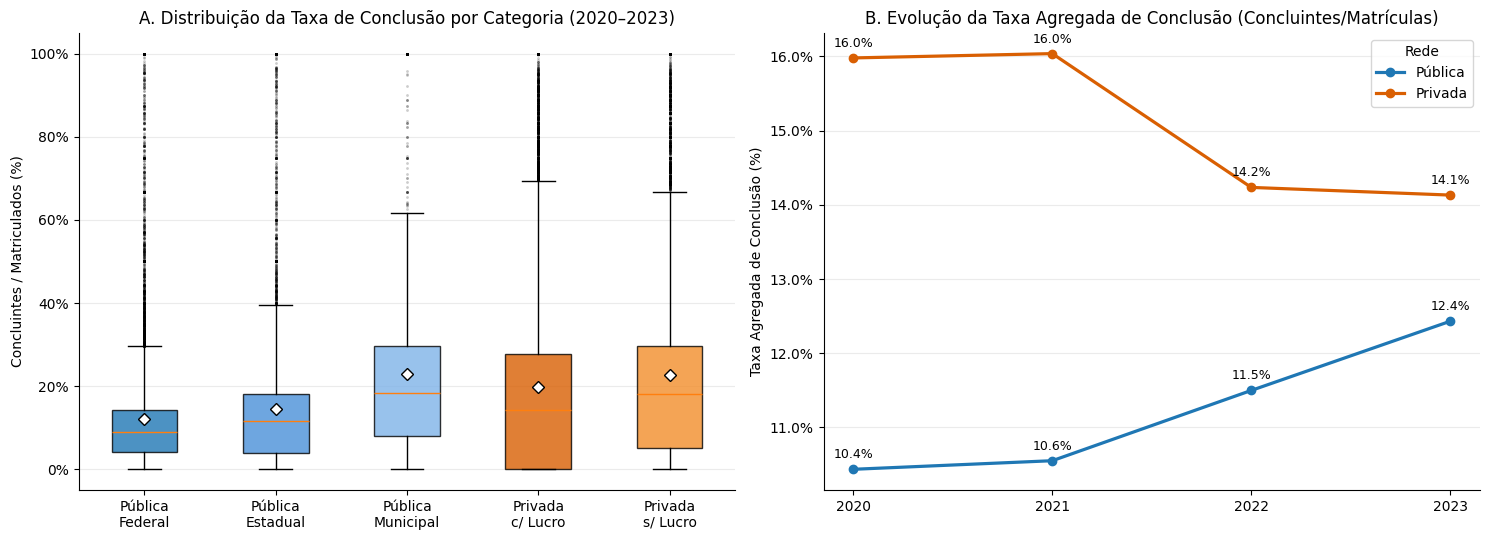

In [ ]:
# Visualização RQ2.1: Distribuição e Evolução Temporal da Taxa de Conclusão
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

ordem_cats = [
    "Pública Federal",
    "Pública Estadual",
    "Pública Municipal",
    "Privada com fins lucrativos",
    "Privada sem fins lucrativos",
]
dados_box = [
    cursos_ativos.loc[cursos_ativos["CATEGORIA_ADM"] == cat, "TAXA_CONC_MAT_PCT"].values
    for cat in ordem_cats
]
bp = axes[0].boxplot(
    dados_box,
    labels=["Pública\nFederal", "Pública\nEstadual", "Pública\nMunicipal", "Privada\nc/ Lucro", "Privada\ns/ Lucro"],
    patch_artist=True,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 6},
    flierprops={"marker": ".", "markersize": 2, "alpha": 0.2}
)
cores_box = ["#1f77b4", "#4a90d9", "#7fb3e8", "#d95f02", "#f28e2b"]
for patch, cor in zip(bp["boxes"], cores_box):
    patch.set_facecolor(cor)
    patch.set_alpha(0.8)
axes[0].set_title("A. Distribuição da Taxa de Conclusão por Categoria (2020–2023)")
axes[0].set_ylabel("Concluintes / Matriculados (%)")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[0].grid(axis="y", alpha=0.25)

rq2_temporal = (
    cursos_ativos.groupby(["NU_ANO_CENSO", "REDE"], observed=True)[["QT_MAT", "QT_CONC"]]
    .sum()
    .reset_index()
)
rq2_temporal["TAXA_MACRO_PCT"] = (rq2_temporal["QT_CONC"] / rq2_temporal["QT_MAT"]) * 100

for rede, cor in [("Pública", "#1f77b4"), ("Privada", "#d95f02")]:
    sub = rq2_temporal[rq2_temporal["REDE"] == rede]
    axes[1].plot(sub["NU_ANO_CENSO"], sub["TAXA_MACRO_PCT"], marker="o", linewidth=2.3, color=cor, label=rede)
    for _, row in sub.iterrows():
        axes[1].annotate(
            f"{row['TAXA_MACRO_PCT']:.1f}%",
            (row["NU_ANO_CENSO"], row["TAXA_MACRO_PCT"]),
            textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9
        )

axes[1].set_title("B. Evolução da Taxa Agregada de Conclusão (Concluintes/Matrículas)")
axes[1].set_ylabel("Taxa Agregada de Conclusão (%)")
axes[1].set_xticks([2020, 2021, 2022, 2023])
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend(title="Rede")

plt.tight_layout()
plt.show()

### 4.2 Complemento RQ2 — Análise Estratificada, Testes Post-Hoc e Regressão Múltipla (OLS Robusto HC3)

Cursos tecnológicos (de menor duração) e cursos EaD possuem dinâmica de integralização distinta dos bacharelados presenciais. Para verificar se a diferença entre instituições públicas e privadas persiste após isolar esses efeitos de composição:

1. **Análise Estratificada (`Modalidade × Grau Acadêmico`):** Calcula correlações e testes de Mann-Whitney $U$ dentro de cada estrato homogêneo (prevenção ao Paradoxo de Simpson).
2. **Comparações Múltiplas Post-Hoc (Bonferroni-Holm):** Compara par a par as categorias administrativas específicas (`Federal`, `Estadual`, `Municipal`, `Privada c/ Lucro`, `Privada s/ Lucro`).
3. **Regressão Linear Múltipla (OLS com erros-padrão robustos HC3):** Modela `TAXA_CONC_MAT_PCT` em função da categoria administrativa (referência: `Pública Federal`), controlando por **modalidade**, **grau acadêmico**, **porte do curso ($\ln(	ext{QT\_MAT})$)**, **área CINE** e **ano do Censo**.

In [ ]:
# 1. Análise Estratificada: Modalidade x Grau Acadêmico (Pública vs. Privada)
estratos_rq2 = []
for (mod, grau), sub in cursos_ativos.groupby(["MODALIDADE", "GRAU_ACADEMICO"], observed=True):
    if grau not in ["Bacharelado", "Licenciatura", "Tecnológico"]:
        continue
    pub_s = sub.loc[sub["REDE"] == "Pública", "TAXA_CONC_MAT_PCT"]
    priv_s = sub.loc[sub["REDE"] == "Privada", "TAXA_CONC_MAT_PCT"]
    if len(pub_s) < 20 or len(priv_s) < 20:
        continue

    r_est, p_r_est = stats.pointbiserialr(sub["REDE_BIN"], sub["TAXA_CONC_MAT_PCT"])
    rho_est, p_rho_est = stats.spearmanr(sub["REDE_BIN"], sub["TAXA_CONC_MAT_PCT"])
    u_est, p_u_est = stats.mannwhitneyu(priv_s, pub_s, alternative="two-sided")
    r_rb_est = 1 - (2 * u_est) / (len(priv_s) * len(pub_s))

    estratos_rq2.append({
        "Modalidade": mod,
        "Grau_Academico": grau,
        "N_Publica": len(pub_s),
        "N_Privada": len(priv_s),
        "Mediana_Publica_%": pub_s.median(),
        "Mediana_Privada_%": priv_s.median(),
        "Diff_Medianas_pp": priv_s.median() - pub_s.median(),
        "Media_Publica_%": pub_s.mean(),
        "Media_Privada_%": priv_s.mean(),
        "Spearman_rho": rho_est,
        "p_valor_MW": p_u_est,
        "Rank_Biserial_r": r_rb_est,
    })

df_estratos_rq2 = pd.DataFrame(estratos_rq2)
print("=== RQ2.4: Correlação e Diferença Estratificada por Modalidade e Grau Acadêmico ===")
display(df_estratos_rq2)

# 2. Comparações Múltiplas Post-Hoc (Mann-Whitney par a par com correção de Holm)
cats_validas = [
    c for c in ordem_cats
    if (cursos_ativos["CATEGORIA_ADM"] == c).sum() >= 30
]
pares = list(combinations(cats_validas, 2))
posthoc_rows = []
for c1, c2 in pares:
    g1 = cursos_ativos.loc[cursos_ativos["CATEGORIA_ADM"] == c1, "TAXA_CONC_MAT_PCT"]
    g2 = cursos_ativos.loc[cursos_ativos["CATEGORIA_ADM"] == c2, "TAXA_CONC_MAT_PCT"]
    u_pair, p_pair = stats.mannwhitneyu(g1, g2, alternative="two-sided")
    posthoc_rows.append({
        "Grupo_A": c1,
        "Grupo_B": c2,
        "Mediana_A_%": g1.median(),
        "Mediana_B_%": g2.median(),
        "Diff_Mediana_AB_pp": g1.median() - g2.median(),
        "p_bruto": p_pair,
    })

df_posthoc = pd.DataFrame(posthoc_rows).sort_values("p_bruto").reset_index(drop=True)
# Correção sequencial de Bonferroni-Holm
m_tests = len(df_posthoc)
p_holm = np.minimum(1.0, np.maximum.accumulate(df_posthoc["p_bruto"].values * np.arange(m_tests, 0, -1)))
df_posthoc["p_ajustado_Holm"] = p_holm
df_posthoc["Significativo_Holm_5%"] = np.where(df_posthoc["p_ajustado_Holm"] < 0.05, "Sim", "Não")

print("\n=== RQ2.5: Comparações Post-Hoc entre Categorias Administrativas (Correção de Holm) ===")
display(df_posthoc)

=== RQ2.4: Correlação e Diferença Estratificada por Modalidade e Grau Acadêmico ===


,Modalidade,Grau_Academico,N_Publica,N_Privada,Mediana_Publica_%,Mediana_Privada_%,Diff_Medianas_pp,Media_Publica_%,Media_Privada_%,Spearman_rho,p_valor_MW,Rank_Biserial_r
0,EaD,Bacharelado,412,9749,2.70,0.00,-2.70,17.03,4.88,-0.11,0.00,0.29
1,EaD,Licenciatura,1642,5299,5.90,0.00,-5.90,16.60,10.26,-0.16,0.00,0.21
2,EaD,Tecnológico,226,14712,3.77,7.69,3.92,15.03,13.85,0.01,0.27,-0.04
3,Presencial,Bacharelado,22715,68427,10.26,17.24,6.98,12.90,20.47,0.19,0.00,-0.25
4,Presencial,Licenciatura,13374,9205,9.72,26.67,16.94,14.25,33.64,0.39,0.00,-0.45
5,Presencial,Tecnológico,4822,16487,11.74,29.09,17.35,15.78,35.27,0.30,0.00,-0.41



=== RQ2.5: Comparações Post-Hoc entre Categorias Administrativas (Correção de Holm) ===


,Grupo_A,Grupo_B,Mediana_A_%,Mediana_B_%,Diff_Mediana_AB_pp,p_bruto,p_ajustado_Holm,Significativo_Holm_5%
0,Pública Federal,Privada sem fins lucrativos,8.97,18.07,-9.10,0.00,0.00,Sim
1,Pública Estadual,Privada sem fins lucrativos,11.54,18.07,-6.53,0.00,0.00,Sim
2,Pública Federal,Privada com fins lucrativos,8.97,14.29,-5.31,0.00,0.00,Sim
3,Privada com fins lucrativos,Privada sem fins lucrativos,14.29,18.07,-3.79,0.00,0.00,Sim
4,Pública Federal,Pública Municipal,8.97,18.40,-9.42,0.00,0.00,Sim
5,Pública Federal,Pública Estadual,8.97,11.54,-2.56,0.00,0.00,Sim
6,Pública Estadual,Pública Municipal,11.54,18.40,-6.86,0.00,0.00,Sim
7,Pública Estadual,Privada com fins lucrativos,11.54,14.29,-2.75,0.00,0.00,Sim
8,Pública Municipal,Privada com fins lucrativos,18.40,14.29,4.11,0.00,0.00,Sim
9,Pública Municipal,Privada sem fins lucrativos,18.40,18.07,0.32,0.12,0.12,Não


In [ ]:
# 3. Modelo de Regressão Linear Múltipla (OLS com erros-padrão robustos HC3)
df_reg_ols = cursos_ativos[
    cursos_ativos["CATEGORIA_ADM"].isin(ordem_cats)
    & cursos_ativos["GRAU_ACADEMICO"].isin(["Bacharelado", "Licenciatura", "Tecnológico"])
].copy()

df_reg_ols["LOG_MAT"] = np.log1p(df_reg_ols["QT_MAT"])

# Categorias de referência explícitas: Pública Federal, Presencial, Bacharelado, Ano 2020
df_reg_ols["CATEGORIA_ADM"] = pd.Categorical(df_reg_ols["CATEGORIA_ADM"], categories=ordem_cats)
df_reg_ols["MODALIDADE"] = pd.Categorical(df_reg_ols["MODALIDADE"], categories=["Presencial", "EaD"])
df_reg_ols["GRAU_ACADEMICO"] = pd.Categorical(
    df_reg_ols["GRAU_ACADEMICO"], categories=["Bacharelado", "Licenciatura", "Tecnológico"]
)
df_reg_ols["NU_ANO_CENSO"] = df_reg_ols["NU_ANO_CENSO"].astype("category")
df_reg_ols["NO_CINE_AREA_GERAL"] = df_reg_ols["NO_CINE_AREA_GERAL"].astype(str).astype("category")

X_df = pd.get_dummies(
    df_reg_ols[["CATEGORIA_ADM", "MODALIDADE", "GRAU_ACADEMICO", "LOG_MAT", "NU_ANO_CENSO", "NO_CINE_AREA_GERAL"]],
    drop_first=True,
    dtype=float
)
X_df.insert(0, "Intercepto", 1.0)

X_mat = X_df.to_numpy(dtype=float)
y_vec = df_reg_ols["TAXA_CONC_MAT_PCT"].to_numpy(dtype=float)
n_obs, p_vars = X_mat.shape

# Estimação via decomposição QR e matriz de covariância robusta HC3
Q, R = np.linalg.qr(X_mat, mode="reduced")
beta = np.linalg.solve(R, Q.T @ y_vec)
y_hat = X_mat @ beta
resid = y_vec - y_hat

leverage = np.sum(Q ** 2, axis=1)
leverage = np.clip(leverage, 0.0, 0.999999)
R_inv = np.linalg.inv(R)
XtX_inv = R_inv @ R_inv.T
weights_hc3 = (resid / (1.0 - leverage)) ** 2
meat_hc3 = (X_mat * weights_hc3[:, None]).T @ X_mat
cov_hc3 = XtX_inv @ meat_hc3 @ XtX_inv

se_hc3 = np.sqrt(np.diag(cov_hc3))
t_vals = beta / se_hc3
p_vals = 2.0 * stats.t.sf(np.abs(t_vals), df=n_obs - p_vars)
t_crit = stats.t.ppf(0.975, df=n_obs - p_vars)

ss_res = np.sum(resid ** 2)
ss_tot = np.sum((y_vec - np.mean(y_vec)) ** 2)
r2 = 1.0 - (ss_res / ss_tot)
r2_adj = 1.0 - (1.0 - r2) * (n_obs - 1) / (n_obs - p_vars)

tabela_ols = pd.DataFrame({
    "Variavel": X_df.columns,
    "Coeficiente_pp": beta,
    "Erro_Padrao_HC3": se_hc3,
    "Estatistica_t": t_vals,
    "p_valor": p_vals,
    "IC95_Inf": beta - t_crit * se_hc3,
    "IC95_Sup": beta + t_crit * se_hc3,
})

# Exibir os principais preditores (excluindo dummies de controle das 11 áreas CINE para leitura limpa)
tabela_ols_principal = tabela_ols[~tabela_ols["Variavel"].str.startswith("NO_CINE_AREA_GERAL_")].copy()
print(f"=== RQ2.6: Regressão Múltipla (OLS Robusto HC3) — N = {n_obs:,} | R² = {r2:.4f} | R² Ajustado = {r2_adj:.4f} ===")
print("Referências: Pública Federal | Presencial | Bacharelado | Ano 2020 | Controle por Área CINE")
display(tabela_ols_principal)

del X_df, X_mat, Q, R
gc.collect()

=== RQ2.6: Regressão Múltipla (OLS Robusto HC3) — N = 166,094 | R² = 0.1654 | R² Ajustado = 0.1653 ===
Referências: Pública Federal | Presencial | Bacharelado | Ano 2020 | Controle por Área CINE


,Variavel,Coeficiente_pp,Erro_Padrao_HC3,Estatistica_t,p_valor,IC95_Inf,IC95_Sup
0,Intercepto,20.79,0.38,54.54,0.00,20.05,21.54
1,LOG_MAT,-3.17,0.05,-59.85,0.00,-3.28,-3.07
2,CATEGORIA_ADM_Pública Estadual,0.87,0.18,4.85,0.00,0.52,1.22
3,CATEGORIA_ADM_Pública Municipal,9.48,0.56,16.95,0.00,8.39,10.58
4,CATEGORIA_ADM_Privada com fins lucrativos,8.19,0.14,56.50,0.00,7.91,8.48
5,CATEGORIA_ADM_Privada sem fins lucrativos,10.25,0.15,66.71,0.00,9.95,10.55
6,MODALIDADE_EaD,-15.90,0.14,-113.38,0.00,-16.18,-15.63
7,GRAU_ACADEMICO_Licenciatura,7.68,1.18,6.50,0.00,5.37,10.00
8,GRAU_ACADEMICO_Tecnológico,7.82,0.17,45.29,0.00,7.48,8.16
9,NU_ANO_CENSO_2021,1.38,0.14,9.70,0.00,1.10,1.66


6873

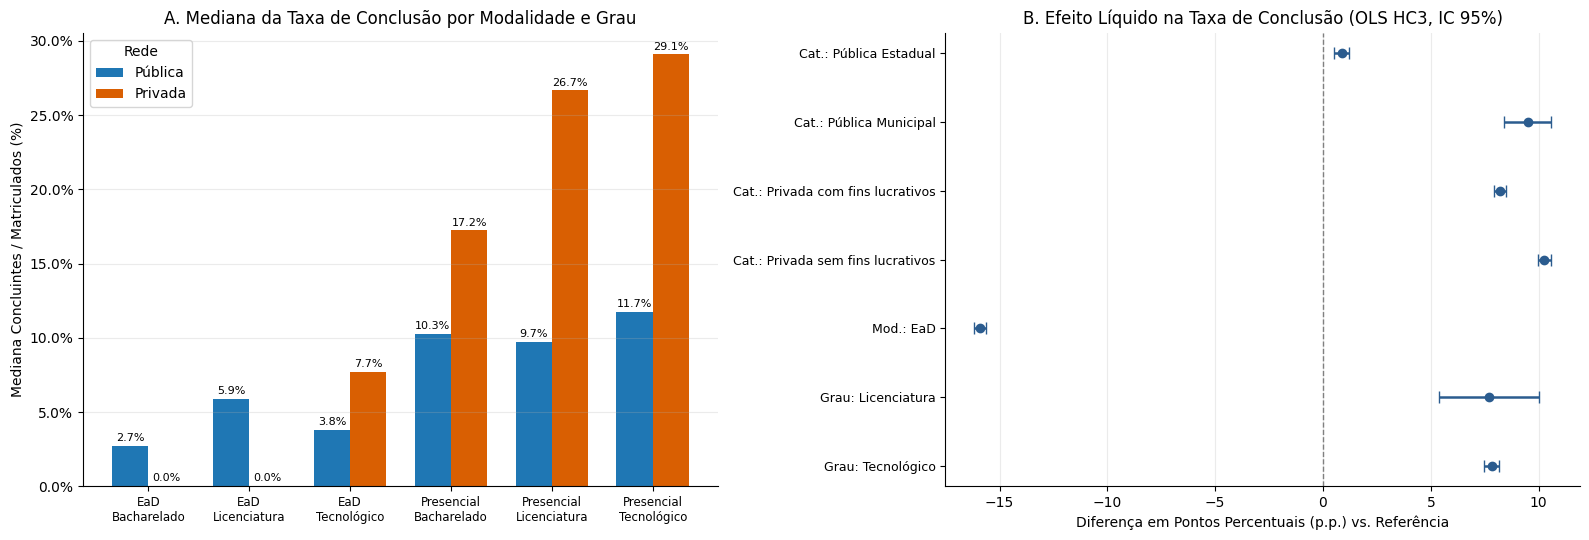

In [ ]:
# Visualização RQ2.2: Taxa Estratificada (Modalidade x Grau) e Coeficientes Líquidos da Regressão
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Painel A: Mediana da Taxa de Conclusão por Modalidade e Grau Acadêmico
df_estratos_rq2["Estrato"] = df_estratos_rq2["Modalidade"].astype(str) + "\n" + df_estratos_rq2["Grau_Academico"].astype(str)
x_pos = np.arange(len(df_estratos_rq2))
largura = 0.36

b1 = axes[0].bar(x_pos - largura/2, df_estratos_rq2["Mediana_Publica_%"], width=largura, color="#1f77b4", label="Pública")
b2 = axes[0].bar(x_pos + largura/2, df_estratos_rq2["Mediana_Privada_%"], width=largura, color="#d95f02", label="Privada")
axes[0].bar_label(b1, fmt="%.1f%%", fontsize=8, padding=2)
axes[0].bar_label(b2, fmt="%.1f%%", fontsize=8, padding=2)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(df_estratos_rq2["Estrato"], fontsize=8.5)
axes[0].set_title("A. Mediana da Taxa de Conclusão por Modalidade e Grau")
axes[0].set_ylabel("Mediana Concluintes / Matriculados (%)")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend(title="Rede")

# Painel B: Efeito Líquido (p.p.) na Regressão Múltipla (Ref.: Pública Federal / Presencial / Bacharelado)
coefs_plot = tabela_ols_principal[
    tabela_ols_principal["Variavel"].str.startswith(("CATEGORIA_ADM_", "MODALIDADE_", "GRAU_ACADEMICO_"))
].copy()
coefs_plot["Label"] = (
    coefs_plot["Variavel"]
    .str.replace("CATEGORIA_ADM_", "Cat.: ", regex=False)
    .str.replace("MODALIDADE_", "Mod.: ", regex=False)
    .str.replace("GRAU_ACADEMICO_", "Grau: ", regex=False)
)
coefs_plot = coefs_plot.iloc[::-1]

y_pos = np.arange(len(coefs_plot))
axes[1].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[1].errorbar(
    coefs_plot["Coeficiente_pp"],
    y_pos,
    xerr=1.96 * coefs_plot["Erro_Padrao_HC3"],
    fmt="o",
    color="#2b5c8f",
    ecolor="#2b5c8f",
    elinewidth=1.8,
    capsize=4
)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(coefs_plot["Label"], fontsize=9)
axes[1].set_title("B. Efeito Líquido na Taxa de Conclusão (OLS HC3, IC 95%)")
axes[1].set_xlabel("Diferença em Pontos Percentuais (p.p.) vs. Referência")
axes[1].grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

## 5. RQ3 — Distribuição Regional da Oferta de Vagas por Modalidade (Presencial vs. EaD) e Rede

**Pergunta de Pesquisa (RQ3):** *Como se distribui a oferta de vagas nas modalidades presencial e a distância quando comparadas entre as redes pública e privada em âmbito regional?*

### 5.1 Composição Interna Regional, Distribuição Geográfica Nacional e Evolução 2020–2023

- **Recorte Geográfico:** Considera as cinco macrorregiões oficiais do IBGE (`Norte`, `Nordeste`, `Centro-Oeste`, `Sudeste`, `Sul`), contabilizando à parte os registros sem região vinculada (`Não informada / Exterior (EaD)`).
- **Matrizes Proporcionais:** Composição interna de cada região (`RQ3.2`, linhas = 100%), distribuição geográfica de cada segmento no Brasil (`RQ3.3`, colunas = 100%) e variação regional 2020–2023 (`RQ3.4`).

In [ ]:
REGIOES_IBGE = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]

# Verificar volume sem região definida (EaD sem polo municipal vinculado / exterior)
vagas_sem_regiao = df_grad.loc[~df_grad["REGIAO"].isin(REGIOES_IBGE), "QT_VG_TOTAL"].sum()
vagas_total_nacional = df_grad["QT_VG_TOTAL"].sum()
print(
    f"Vagas EaD sem região informada/exterior (2020–2023): {vagas_sem_regiao:,} "
    f"({(vagas_sem_regiao / vagas_total_nacional) * 100:.2f}% do total nacional)"
)

df_reg = df_grad[df_grad["REGIAO"].isin(REGIOES_IBGE)].copy()
df_reg["REGIAO"] = df_reg["REGIAO"].astype(str)
df_reg["SEGMENTO"] = df_reg["REDE"].astype(str) + " — " + df_reg["MODALIDADE"].astype(str)

ordem_segmentos = [
    "Pública — Presencial",
    "Pública — EaD",
    "Privada — Presencial",
    "Privada — EaD",
]

# 1. Tabela consolidada 2020-2023 por Região x Segmento
piv_reg_abs = (
    df_reg.pivot_table(
        index="REGIAO",
        columns="SEGMENTO",
        values="QT_VG_TOTAL",
        aggfunc="sum",
        fill_value=0
    )
    .reindex(index=REGIOES_IBGE, columns=ordem_segmentos)
)
piv_reg_abs["Total_Regiao"] = piv_reg_abs.sum(axis=1)

# Composição percentual interna de cada região (linhas somam 100%)
piv_reg_comp_pct = piv_reg_abs[ordem_segmentos].div(piv_reg_abs["Total_Regiao"], axis=0) * 100

# Distribuição geográfica de cada segmento entre as regiões (colunas somam 100%)
piv_reg_dist_brasil_pct = piv_reg_abs[ordem_segmentos].div(piv_reg_abs[ordem_segmentos].sum(axis=0), axis=1) * 100

print("\n=== RQ3.1: Volume Absoluto de Vagas Ofertadas por Região, Rede e Modalidade (2020–2023) ===")
display(piv_reg_abs)

print("\n=== RQ3.2: Composição Interna da Oferta de Vagas em Cada Região (% — linhas = 100%) ===")
display(piv_reg_comp_pct)

print("\n=== RQ3.3: Distribuição Geográfica de Cada Segmento pelo Brasil (% — colunas = 100%) ===")
display(piv_reg_dist_brasil_pct)

Vagas EaD sem região informada/exterior (2020–2023): 66,606,011 (74.21% do total nacional)

=== RQ3.1: Volume Absoluto de Vagas Ofertadas por Região, Rede e Modalidade (2020–2023) ===


SEGMENTO,Pública — Presencial,Pública — EaD,Privada — Presencial,Privada — EaD,Total_Regiao
REGIAO,,,,,
Norte,251251,0,1855374,0,2106625
Nordeste,826354,0,4642406,0,5468760
Centro-Oeste,315696,0,1694026,0,2009722
Sudeste,1044854,0,9745659,0,10790513
Sul,570628,0,2203006,0,2773634



=== RQ3.2: Composição Interna da Oferta de Vagas em Cada Região (% — linhas = 100%) ===


SEGMENTO,Pública — Presencial,Pública — EaD,Privada — Presencial,Privada — EaD
REGIAO,,,,
Norte,11.93,0.00,88.07,0.00
Nordeste,15.11,0.00,84.89,0.00
Centro-Oeste,15.71,0.00,84.29,0.00
Sudeste,9.68,0.00,90.32,0.00
Sul,20.57,0.00,79.43,0.00



=== RQ3.3: Distribuição Geográfica de Cada Segmento pelo Brasil (% — colunas = 100%) ===


SEGMENTO,Pública — Presencial,Pública — EaD,Privada — Presencial,Privada — EaD
REGIAO,,,,
Norte,8.35,NaN,9.21,NaN
Nordeste,27.46,NaN,23.05,NaN
Centro-Oeste,10.49,NaN,8.41,NaN
Sudeste,34.73,NaN,48.39,NaN
Sul,18.97,NaN,10.94,NaN


In [ ]:
# 2. Evolução Regional (2020 vs. 2023) por Rede e Modalidade
reg_2020_2023 = (
    df_reg[df_reg["NU_ANO_CENSO"].isin([2020, 2023])]
    .pivot_table(
        index=["REGIAO", "REDE", "MODALIDADE"],
        columns="NU_ANO_CENSO",
        values="QT_VG_TOTAL",
        aggfunc="sum",
        observed=True,
        fill_value=0
    )
    .reset_index()
)
reg_2020_2023["Variacao_2020_2023_%"] = (
    (reg_2020_2023[2023] / reg_2020_2023[2020].replace(0, np.nan)) - 1
) * 100

print("=== RQ3.4: Evolução Regional das Vagas Ofertadas (2020 vs. 2023) ===")
display(reg_2020_2023.sort_values(["REGIAO", "REDE", "MODALIDADE"]))

=== RQ3.4: Evolução Regional das Vagas Ofertadas (2020 vs. 2023) ===


NU_ANO_CENSO,REGIAO,REDE,MODALIDADE,2020,2023,Variacao_2020_2023_%
0,Centro-Oeste,Privada,EaD,0,0,NaN
1,Centro-Oeste,Privada,Presencial,450705,411726,-8.65
2,Centro-Oeste,Pública,EaD,0,0,NaN
3,Centro-Oeste,Pública,Presencial,68861,89373,29.79
4,Nordeste,Privada,EaD,0,0,NaN
5,Nordeste,Privada,Presencial,1153846,1073737,-6.94
6,Nordeste,Pública,EaD,0,0,NaN
7,Nordeste,Pública,Presencial,207623,210099,1.19
8,Norte,Privada,EaD,0,0,NaN
9,Norte,Privada,Presencial,449130,419638,-6.57


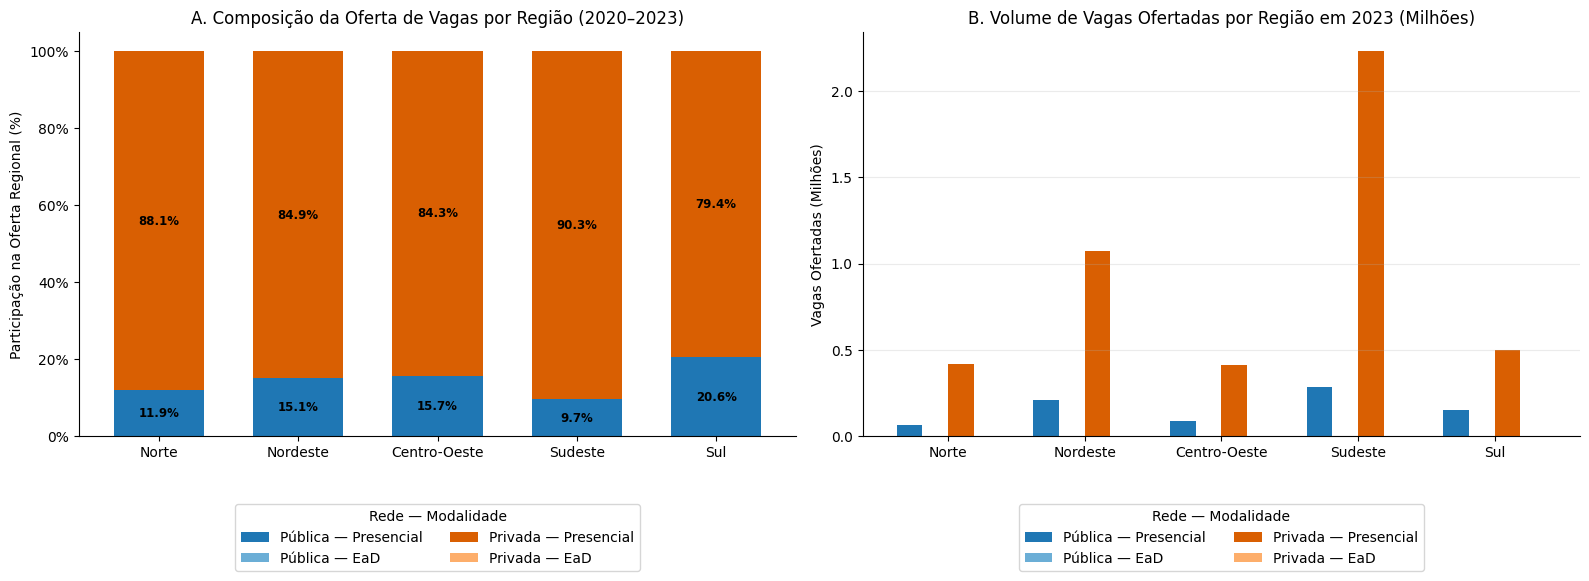

In [ ]:
# Visualização RQ3.1: Composição Regional e Comparação Presencial vs. EaD
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
cores_seg = ["#1f77b4", "#6baed6", "#d95f02", "#fdae6b"]

piv_reg_comp_pct.plot(
    kind="bar",
    stacked=True,
    ax=axes[0],
    color=cores_seg,
    width=0.65
)
axes[0].set_title("A. Composição da Oferta de Vagas por Região (2020–2023)")
axes[0].set_ylabel("Participação na Oferta Regional (%)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())
for container in axes[0].containers:
    labels = [f"{v:.1f}%" if v >= 5.0 else "" for v in container.datavalues]
    axes[0].bar_label(container, labels=labels, label_type="center", fontsize=8.5, fontweight="bold")
axes[0].legend(title="Rede — Modalidade", bbox_to_anchor=(0.5, -0.15), loc="upper center", ncol=2)

piv_2023_reg = (
    df_reg[df_reg["NU_ANO_CENSO"] == 2023]
    .pivot_table(index="REGIAO", columns="SEGMENTO", values="QT_VG_TOTAL", aggfunc="sum", fill_value=0)
    .reindex(index=REGIOES_IBGE, columns=ordem_segmentos) / 1e6
)
piv_2023_reg.plot(
    kind="bar",
    ax=axes[1],
    color=cores_seg,
    width=0.75
)
axes[1].set_title("B. Volume de Vagas Ofertadas por Região em 2023 (Milhões)")
axes[1].set_ylabel("Vagas Ofertadas (Milhões)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend(title="Rede — Modalidade", bbox_to_anchor=(0.5, -0.15), loc="upper center", ncol=2)

plt.tight_layout()
plt.show()

### 5.2 Complemento RQ3 — Quociente Locacional (QL), Oferta vs. Captação Efetiva, UFs e Capital vs. Interior

Para aprofundar a dimensão territorial da oferta presencial e EaD:
1. **Quociente Locacional (QL):** Mede a especialização relativa de cada região em cada segmento (`QL > 1,0` indica concentração acima da média nacional).
2. **Oferta vs. Captação Efetiva Regional:** Contrasta a proporção regional de **vagas ofertadas (`QT_VG_TOTAL`)** com a proporção de **ingressantes (`QT_ING`)** e calcula a **taxa de ocupação regional** por segmento.
3. **Desagregação por Unidade da Federação (`SG_UF`) e Capital vs. Interior (`IN_CAPITAL`):** Mostra como o avanço do EaD privado e a presença da rede pública presencial se comportam entre capitais, municípios do interior e estados.

In [ ]:
# 1. Quociente Locacional (QL) e Razão Privada/Pública por Região (2020–2023)
share_nacional_seg = piv_reg_abs[ordem_segmentos].sum(axis=0) / piv_reg_abs["Total_Regiao"].sum()
share_interno_reg = piv_reg_abs[ordem_segmentos].div(piv_reg_abs["Total_Regiao"], axis=0)
ql_regiao = share_interno_reg.div(share_nacional_seg, axis=1)

ql_regiao["Razao_Privada_Publica"] = (
    (piv_reg_abs["Privada — Presencial"] + piv_reg_abs["Privada — EaD"])
    / (piv_reg_abs["Pública — Presencial"] + piv_reg_abs["Pública — EaD"]).replace(0, np.nan)
)

print("=== RQ3.5: Quociente Locacional (QL) e Razão Privada/Pública por Região (2020–2023) ===")
display(ql_regiao)

# 2. Oferta de Vagas vs. Ingressantes Efetivos e Taxa de Ocupação por Região e Segmento (2020–2023)
reg_efetivo = (
    df_reg.groupby(["REGIAO", "SEGMENTO"], observed=True)[["QT_VG_TOTAL", "QT_ING", "QT_MAT"]]
    .sum()
    .reset_index()
)
reg_efetivo["Taxa_Ocupacao_%"] = (reg_efetivo["QT_ING"] / reg_efetivo["QT_VG_TOTAL"].replace(0, np.nan)) * 100
piv_ocupacao_reg = (
    reg_efetivo.pivot(index="REGIAO", columns="SEGMENTO", values="Taxa_Ocupacao_%")
    .reindex(index=REGIOES_IBGE, columns=ordem_segmentos)
)

print("\n=== RQ3.6: Taxa de Ocupação (Ingressantes / Vagas %) por Região e Segmento (2020–2023) ===")
display(piv_ocupacao_reg)

# 3. Recorte Capital vs. Interior (IN_CAPITAL) por Rede e Modalidade
cap_int = (
    df_reg[df_reg["LOCALIDADE"].isin(["Capital", "Interior"])]
    .pivot_table(
        index=["LOCALIDADE", "REDE"],
        columns="MODALIDADE",
        values=["QT_VG_TOTAL", "QT_ING"],
        aggfunc="sum",
        observed=True,
        fill_value=0
    )
)
res_cap_int = pd.DataFrame(index=cap_int.index)
res_cap_int["Vagas_Presencial"] = cap_int[("QT_VG_TOTAL", "Presencial")]
res_cap_int["Vagas_EaD"] = cap_int[("QT_VG_TOTAL", "EaD")]
res_cap_int["Share_EaD_nas_Vagas_%"] = (
    res_cap_int["Vagas_EaD"] / (res_cap_int["Vagas_Presencial"] + res_cap_int["Vagas_EaD"]).replace(0, np.nan)
) * 100
res_cap_int["Ing_Presencial"] = cap_int[("QT_ING", "Presencial")]
res_cap_int["Ing_EaD"] = cap_int[("QT_ING", "EaD")]

print("\n=== RQ3.7: Oferta de Vagas e Ingressantes — Capital vs. Interior (2020–2023) ===")
display(res_cap_int)

=== RQ3.5: Quociente Locacional (QL) e Razão Privada/Pública por Região (2020–2023) ===


SEGMENTO,Pública — Presencial,Pública — EaD,Privada — Presencial,Privada — EaD,Razao_Privada_Publica
REGIAO,,,,,
Norte,0.92,NaN,1.01,NaN,7.38
Nordeste,1.16,NaN,0.98,NaN,5.62
Centro-Oeste,1.21,NaN,0.97,NaN,5.37
Sudeste,0.75,NaN,1.04,NaN,9.33
Sul,1.58,NaN,0.91,NaN,3.86



=== RQ3.6: Taxa de Ocupação (Ingressantes / Vagas %) por Região e Segmento (2020–2023) ===


SEGMENTO,Pública — Presencial,Pública — EaD,Privada — Presencial,Privada — EaD
REGIAO,,,,
Norte,63.28,NaN,16.96,NaN
Nordeste,61.03,NaN,19.71,NaN
Centro-Oeste,59.17,NaN,25.50,NaN
Sudeste,67.22,NaN,24.66,NaN
Sul,55.19,NaN,28.47,NaN



=== RQ3.7: Oferta de Vagas e Ingressantes — Capital vs. Interior (2020–2023) ===


Vagas_Presencial  Vagas_EaD  Share_EaD_nas_Vagas_%  \
LOCALIDADE REDE                                                          
Capital    Privada          10517357          0                   0.00   
           Pública            921864          0                   0.00   
Interior   Privada           9623114          0                   0.00   
           Pública           2086919          0                   0.00   

                    Ing_Presencial  Ing_EaD  
LOCALIDADE REDE                              
Capital    Privada         2377149  3256771  
           Pública          675160    47811  
Interior   Privada         2315167  7391784  
           Pública         1192305   198360

In [ ]:
# 4. Ranking por Unidade da Federação (SG_UF): Vagas 2020 vs. 2023 por Rede e Modalidade
uf_comp = (
    df_reg[df_reg["NU_ANO_CENSO"].isin([2020, 2023])]
    .pivot_table(
        index=["REGIAO", "SG_UF"],
        columns=["NU_ANO_CENSO", "REDE", "MODALIDADE"],
        values="QT_VG_TOTAL",
        aggfunc="sum",
        observed=True,
        fill_value=0
    )
)

res_uf = pd.DataFrame(index=uf_comp.index)
res_uf["Pub_Pres_2023"] = uf_comp.get((2023, "Pública", "Presencial"), 0)
res_uf["Pub_EaD_2023"] = uf_comp.get((2023, "Pública", "EaD"), 0)
res_uf["Priv_Pres_2023"] = uf_comp.get((2023, "Privada", "Presencial"), 0)
res_uf["Priv_EaD_2023"] = uf_comp.get((2023, "Privada", "EaD"), 0)
res_uf["Total_Vagas_2023"] = res_uf.sum(axis=1)
res_uf["Share_Publica_2023_%"] = (
    (res_uf["Pub_Pres_2023"] + res_uf["Pub_EaD_2023"]) / res_uf["Total_Vagas_2023"].replace(0, np.nan)
) * 100
res_uf["Share_EaD_Priv_2023_%"] = (
    res_uf["Priv_EaD_2023"] / res_uf["Total_Vagas_2023"].replace(0, np.nan)
) * 100

vagas_2020_uf = uf_comp.xs(2020, level=0, axis=1).sum(axis=1)
res_uf["Var_Vagas_Total_2020_2023_%"] = ((res_uf["Total_Vagas_2023"] / vagas_2020_uf.replace(0, np.nan)) - 1) * 100

print("=== RQ3.8: Panorama por Unidade da Federação (Ordenado por Total de Vagas em 2023) ===")
display(res_uf.sort_values("Total_Vagas_2023", ascending=False))

=== RQ3.8: Panorama por Unidade da Federação (Ordenado por Total de Vagas em 2023) ===


Pub_Pres_2023  Pub_EaD_2023  Priv_Pres_2023  \
REGIAO       SG_UF                                                
Sudeste      SP            112619             0         1327281   
             RJ             52129             0          498453   
             MG             87863             0          331805   
Nordeste     PE             33844             0          254191   
             BA             41107             0          241449   
Sul          PR             54254             0          205984   
Nordeste     CE             28813             0          217911   
Sul          RS             61395             0          171072   
Centro-Oeste GO             38784             0          162153   
Norte        PA             28307             0          163686   
Sul          SC             39178             0          123663   
Centro-Oeste DF             14093             0          148548   
Norte        AM              9661             0          119053   
Nordeste     MA             20310             0           92884   
Sudeste      ES             30964             0           71257   
Nordeste     PB             29785             0           61759   
Centro-Oeste MT             19612             0           64706   
Nordeste     PI             15494             0           63301   
             RN             18941             0           52767   
             AL             11372             0           46144   
Norte        RO              6862             0           47675   
Nordeste     SE             10433             0           43331   
Centro-Oeste MS             16884             0           36319   
Norte        AC              3846             0           35068   
             TO             11263             0           23438   
             AP              4878             0           15106   
             RR              3262             0           15612   

                    Priv_EaD_2023  Total_Vagas_2023  Share_Publica_2023_%  \
REGIAO       SG_UF                                                          
Sudeste      SP                 0           1439900                  7.82   
             RJ                 0            550582                  9.47   
             MG                 0            419668                 20.94   
Nordeste     PE                 0            288035                 11.75   
             BA                 0            282556                 14.55   
Sul          PR                 0            260238                 20.85   
Nordeste     CE                 0            246724                 11.68   
Sul          RS                 0            232467                 26.41   
Centro-Oeste GO                 0            200937                 19.30   
Norte        PA                 0            191993                 14.74   
Sul          SC                 0            162841                 24.06   
Centro-Oeste DF                 0            162641                  8.67   
Norte        AM                 0            128714                  7.51   
Nordeste     MA                 0            113194                 17.94   
Sudeste      ES                 0            102221                 30.29   
Nordeste     PB                 0             91544                 32.54   
Centro-Oeste MT                 0             84318                 23.26   
Nordeste     PI                 0             78795                 19.66   
             RN                 0             71708                 26.41   
             AL                 0             57516                 19.77   
Norte        RO                 0             54537                 12.58   
Nordeste     SE                 0             53764                 19.41   
Centro-Oeste MS                 0             53203                 31.74   
Norte        AC                 0             38914                  9.88   
             TO                 0             34701                 32.46 

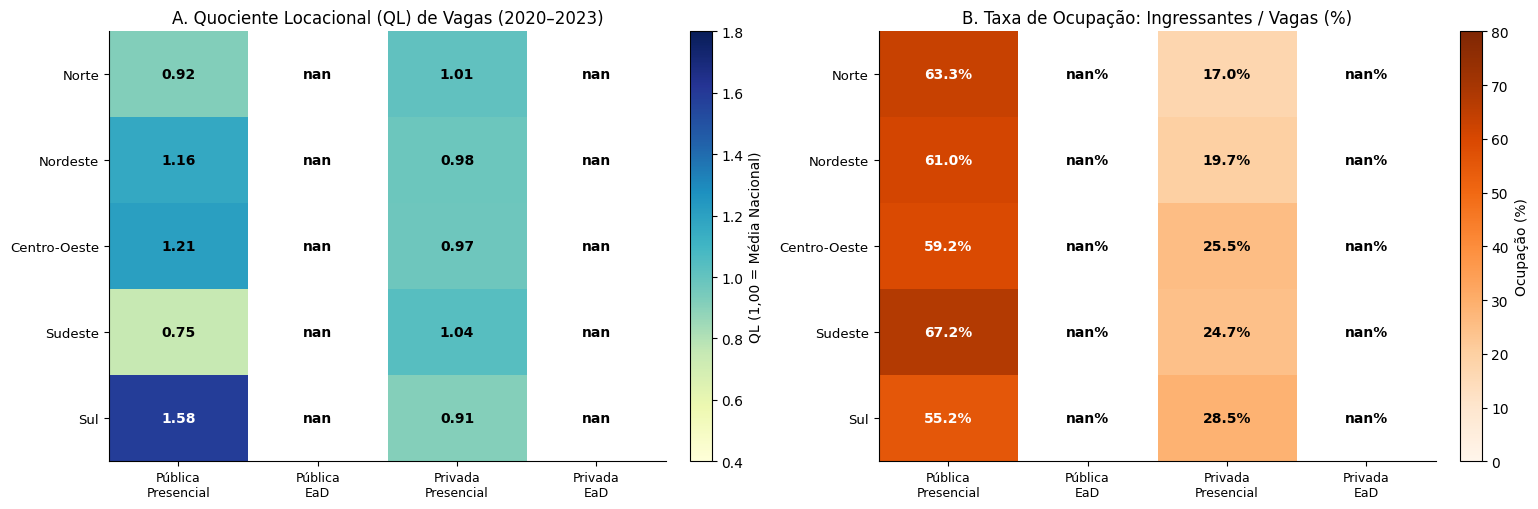

In [ ]:
# Visualização RQ3.2: Heatmap de Quociente Locacional (QL) e Taxa de Ocupação Regional
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))

# Painel A: Heatmap do Quociente Locacional (QL)
ql_vals = ql_regiao[ordem_segmentos].to_numpy()
im1 = axes[0].imshow(ql_vals, cmap="YlGnBu", aspect="auto", vmin=0.4, vmax=1.8)
axes[0].set_xticks(np.arange(len(ordem_segmentos)))
axes[0].set_xticklabels(["Pública\nPresencial", "Pública\nEaD", "Privada\nPresencial", "Privada\nEaD"], fontsize=9)
axes[0].set_yticks(np.arange(len(REGIOES_IBGE)))
axes[0].set_yticklabels(REGIOES_IBGE, fontsize=9.5)
axes[0].set_title("A. Quociente Locacional (QL) de Vagas (2020–2023)")
for i in range(ql_vals.shape[0]):
    for j in range(ql_vals.shape[1]):
        cor_txt = "white" if ql_vals[i, j] > 1.25 else "black"
        axes[0].text(j, i, f"{ql_vals[i, j]:.2f}", ha="center", va="center", color=cor_txt, fontweight="bold")
fig.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04, label="QL (1,00 = Média Nacional)")

# Painel B: Heatmap da Taxa de Ocupação (Ingressantes / Vagas %)
oc_vals = piv_ocupacao_reg[ordem_segmentos].to_numpy()
im2 = axes[1].imshow(oc_vals, cmap="Oranges", aspect="auto", vmin=0, vmax=80)
axes[1].set_xticks(np.arange(len(ordem_segmentos)))
axes[1].set_xticklabels(["Pública\nPresencial", "Pública\nEaD", "Privada\nPresencial", "Privada\nEaD"], fontsize=9)
axes[1].set_yticks(np.arange(len(REGIOES_IBGE)))
axes[1].set_yticklabels(REGIOES_IBGE, fontsize=9.5)
axes[1].set_title("B. Taxa de Ocupação: Ingressantes / Vagas (%)")
for i in range(oc_vals.shape[0]):
    for j in range(oc_vals.shape[1]):
        cor_txt = "white" if oc_vals[i, j] > 50 else "black"
        axes[1].text(j, i, f"{oc_vals[i, j]:.1f}%", ha="center", va="center", color=cor_txt, fontweight="bold")
fig.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04, label="Ocupação (%)")

plt.tight_layout()
plt.show()

## 6. Painel-Síntese Automatizado das Respostas às Perguntas de Pesquisa (RQ1, RQ2 e RQ3)

A célula abaixo consolida automaticamente, em memória, os principais resultados numéricos e estatísticos obtidos nas seções anteriores para cada pergunta de pesquisa.

In [ ]:
# Síntese automatizada das principais métricas de RQ1, RQ2 e RQ3
var_vg_pub = resumo_rq1.loc["Pública", "Var_Acum_Vagas_%"]
var_vg_priv = resumo_rq1.loc["Privada", "Var_Acum_Vagas_%"]
var_ing_pub = resumo_rq1.loc["Pública", "Var_Acum_Ing_%"]
var_ing_priv = resumo_rq1.loc["Privada", "Var_Acum_Ing_%"]
contrib_ead_priv_vg = res_decomp_mod.loc[("Privada", "EaD"), "Contrib_Cresc_Vagas_%"]

med_conc_pub = desc_rede_rq2.loc["Pública", "Mediana_Taxa_Curso_PCT"]
med_conc_priv = desc_rede_rq2.loc["Privada", "Mediana_Taxa_Curso_PCT"]
macro_conc_pub = desc_rede_rq2.loc["Pública", "Taxa_Macro_Ponderada_PCT"]
macro_conc_priv = desc_rede_rq2.loc["Privada", "Taxa_Macro_Ponderada_PCT"]

reg_maior_pub_pres = piv_reg_comp_pct["Pública — Presencial"].idxmax()
pct_maior_pub_pres = piv_reg_comp_pct["Pública — Presencial"].max()
reg_maior_priv_ead = piv_reg_comp_pct["Privada — EaD"].idxmax()
pct_maior_priv_ead = piv_reg_comp_pct["Privada — EaD"].max()
reg_lider_vol = piv_reg_dist_brasil_pct["Privada — EaD"].idxmax()
pct_lider_vol = piv_reg_dist_brasil_pct["Privada — EaD"].max()

painel_sintese_rqs = pd.DataFrame([
    {
        "Pergunta": "RQ1 (Evolução Vagas e Ingressos)",
        "Indicador_Chave": f"Vagas: Privada {var_vg_priv:+.1f}% vs. Pública {var_vg_pub:+.1f}% | Ing.: Privada {var_ing_priv:+.1f}% vs. Pública {var_ing_pub:+.1f}%",
        "Metrica_Estatistica": f"Diferença: {diff_vagas_pp:+.2f} p.p. (vagas) e {diff_ing_pp:+.2f} p.p. (ingressantes)",
        "Achado_Principal": f"O segmento Privada EaD respondeu por {contrib_ead_priv_vg:.1f}% do crescimento líquido de vagas (2020–2023)."
    },
    {
        "Pergunta": "RQ2 (Categoria Adm. x Conclusão)",
        "Indicador_Chave": f"Taxa Agregada: Pública {macro_conc_pub:.1f}% vs. Privada {macro_conc_priv:.1f}% | Mediana: {med_conc_pub:.1f}% vs. {med_conc_priv:.1f}%",
        "Metrica_Estatistica": f"r_pb = {r_pb:+.4f} (p={p_r_pb:.2e}) | Spearman rho = {rho_sp:+.4f} | r_rb = {r_rank_biserial:+.4f}",
        "Achado_Principal": ("Associação estatisticamente significativa (p < 0,05), sensível à composição por modalidade e grau acadêmico." if p_r_pb < 0.05 else "Sem associação linear global significativa (p >= 0,05); avaliar recortes por modalidade e grau.")
    },
    {
        "Pergunta": "RQ3 (Distribuição Regional e Modalidade)",
        "Indicador_Chave": f"Maior peso Pública Presencial: {reg_maior_pub_pres} ({pct_maior_pub_pres:.1f}%) | Maior peso Privada EaD: {reg_maior_priv_ead} ({pct_maior_priv_ead:.1f}%)",
        "Metrica_Estatistica": f"Concentração nacional Privada EaD: {reg_lider_vol} detém {pct_lider_vol:.1f}% das vagas",
        "Achado_Principal": "Forte heterogeneidade regional: Norte/Nordeste têm maior peso relativo público presencial; EaD privado domina todas as regiões."
    },
])

print("=== QUADRO-SÍNTESE AUTOMATIZADO DOS RESULTADOS (2020–2023) ===")
display(painel_sintese_rqs)

=== QUADRO-SÍNTESE AUTOMATIZADO DOS RESULTADOS (2020–2023) ===


,Pergunta,Indicador_Chave,Metrica_Estatistica,Achado_Principal
0,RQ1 (Evolução Vagas e Ingressos),Vagas: Privada +26.2% vs. Pública +8.8% | Ing....,Diferença: +17.37 p.p. (vagas) e +28.65 p.p. (...,O segmento Privada EaD respondeu por 113.5% do...
1,RQ2 (Categoria Adm. x Conclusão),Taxa Agregada: Pública 11.2% vs. Privada 15.0%...,r_pb = +0.1451 (p=0.00e+00) | Spearman rho = +...,Associação estatisticamente significativa (p <...
2,RQ3 (Distribuição Regional e Modalidade),Maior peso Pública Presencial: Sul (20.6%) | M...,Concentração nacional Privada EaD: nan detém n...,Forte heterogeneidade regional: Norte/Nordeste...
